# HERMES Evaluation Visualizations

This notebook presents the evaluation results of **HERMES**, a modular multi-agent GeoAI system for interpretable disaster damage assessment.

The evaluation is organized around **six completed evaluation blocks**:

1. **GeoPerception Agent — hazard classification**
   - Multi-hazard classification over disaster categories

2. **GeoPerception Agent — input-mode recognition**
   - Recognition of the input evidence configuration

3. **GeoDamageAnalysis Agent — severity evaluation**
   - Exact severity accuracy
   - Normalized Cross-Severity Error (NCSE)

4. **GeoDamageAnalysis Agent — object-indicator evaluation**
   - Multi-label precision, recall, F1-score, and accuracy

5. **GeoReasoning Agent — internal consistency evaluation**
   - Factual consistency
   - Causal plausibility
   - Completeness
   - Action feasibility

6. **GeoReasoning Agent — strict operational quality evaluation**
   - Operational specificity
   - Evidence-action alignment
   - Uncertainty and risk handling
   - Decision-support value

The purpose of this notebook is to generate thesis-ready tables, charts, and confusion matrices from the stored HERMES evaluation outputs.

## 1. Setup

This section imports the required Python libraries, defines the project paths, and creates the output directory for exported figures.

All figures generated by this notebook will be saved under:

`figures/evaluation_visualizations/`


In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# If the notebook is executed from /notebooks, move one level up.
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name.lower() == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

EVAL_DIR = PROJECT_ROOT / "evaluation"
FIG_DIR = PROJECT_ROOT / "figures" / "evaluation_visualizations"

FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 160)

print(f"Current directory: {CURRENT_DIR}")
print(f"Project root: {PROJECT_ROOT}")
print(f"Evaluation directory: {EVAL_DIR}")
print(f"Figure output directory: {FIG_DIR}")

Current directory: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\notebooks
Project root: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes
Evaluation directory: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\evaluation
Figure output directory: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations


## 2. Helper Functions and Metric File Inventory

This section defines reusable helper functions for loading CSV files, saving figures, and checking that all required evaluation metric files are available.

The notebook expects to be executed from the HERMES project root:

`E:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes`

In [2]:
def load_csv(relative_path, required=True):
    """
    Load a CSV file relative to the HERMES project root.
    """
    path = PROJECT_ROOT / relative_path
    
    if not path.exists():
        message = f"Missing file: {relative_path}"
        if required:
            raise FileNotFoundError(message)
        print(f"WARNING: {message}")
        return None
    
    return pd.read_csv(path)


def clean_columns(df):
    """
    Strip whitespace from dataframe column names.
    """
    df = df.copy()
    df.columns = [str(c).strip() for c in df.columns]
    return df


def coerce_numeric(df, columns):
    """
    Convert selected columns to numeric values.
    """
    df = df.copy()
    for col in columns:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    return df


def save_fig(filename):
    """
    Save the current matplotlib figure to the thesis figures folder.
    """
    path = FIG_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Saved figure: {path}")
    plt.show()


def find_first_existing_column(df, candidates):
    """
    Return the first column from candidates that exists in df.
    """
    for col in candidates:
        if col in df.columns:
            return col
    return None

In [3]:
metric_files = {
    # Evaluation 1 — GPA hazard classification
    "GPA hazard metrics": "evaluation/hermes_gpa_hazard_full_metrics.csv",
    "GPA hazard confusion matrix": "evaluation/hermes_gpa_hazard_full_confusion_matrix.csv",

    # Evaluation 2 — GPA input-mode recognition
    "GPA mode metrics": "evaluation/hermes_gpa_mode_full_metrics.csv",
    "GPA mode confusion matrix": "evaluation/hermes_gpa_mode_full_confusion_matrix.csv",

    # Evaluation 3 — GDAA severity evaluation
    "GDAA severity metrics": "evaluation/hermes_gdaa_severity_full_metrics.csv",
    "GDAA severity confusion matrix": "evaluation/hermes_gdaa_severity_full_confusion_matrix.csv",
    "GDAA severity by scenario": "evaluation/hermes_gdaa_severity_full_by_scenario.csv",

    # Evaluation 4 — GDAA object-indicator evaluation
    "GDAA object metrics": "evaluation/hermes_gdaa_object_indicator_full_metrics.csv",
    "GDAA object by scenario": "evaluation/hermes_gdaa_object_indicator_full_by_scenario.csv",

    # Evaluation 5 — GRA internal consistency evaluation
    "GRA internal scores": "evaluation/gra_report_evaluation_set/rubric_evaluation/gra_report_rubric_scores.csv",
    "GRA internal by scenario": "evaluation/gra_report_evaluation_set/rubric_evaluation/gra_report_rubric_by_scenario.csv",
    "GRA internal verdict counts": "evaluation/gra_report_evaluation_set/rubric_evaluation/gra_report_rubric_verdict_counts.csv",
    "GRA internal lowest reports": "evaluation/gra_report_evaluation_set/rubric_evaluation/gra_report_rubric_lowest_reports.csv",

    # Evaluation 6 — GRA strict operational quality evaluation
    "GRA strict scores": "evaluation/gra_report_evaluation_set/strict_operational_evaluation/gra_strict_operational_scores.csv",
    "GRA strict by scenario": "evaluation/gra_report_evaluation_set/strict_operational_evaluation/gra_strict_operational_by_scenario.csv",
    "GRA strict verdict counts": "evaluation/gra_report_evaluation_set/strict_operational_evaluation/gra_strict_operational_verdict_counts.csv",
    "GRA strict lowest reports": "evaluation/gra_report_evaluation_set/strict_operational_evaluation/gra_strict_operational_lowest_reports.csv",
}

inventory_rows = []

for name, relative_path in metric_files.items():
    path = PROJECT_ROOT / relative_path
    
    inventory_rows.append({
        "evaluation_file": name,
        "relative_path": relative_path,
        "exists": path.exists(),
        "size_kb": round(path.stat().st_size / 1024, 2) if path.exists() else None,
    })

inventory_df = pd.DataFrame(inventory_rows)
inventory_df

,evaluation_file,relative_path,exists,size_kb
0,GPA hazard metrics,evaluation/hermes_gpa_hazard_full_metrics.csv,False,NaN
1,GPA hazard confusion matrix,evaluation/hermes_gpa_hazard_full_confusion_matrix.csv,False,NaN
2,GPA mode metrics,evaluation/hermes_gpa_mode_full_metrics.csv,False,NaN
3,GPA mode confusion matrix,evaluation/hermes_gpa_mode_full_confusion_matrix.csv,False,NaN
4,GDAA severity metrics,evaluation/hermes_gdaa_severity_full_metrics.csv,True,1.22
5,GDAA severity confusion matrix,evaluation/hermes_gdaa_severity_full_confusion_matrix.csv,True,0.50
6,GDAA severity by scenario,evaluation/hermes_gdaa_severity_full_by_scenario.csv,True,0.22
7,GDAA object metrics,evaluation/hermes_gdaa_object_indicator_full_metrics.csv,True,1.63
8,GDAA object by scenario,evaluation/hermes_gdaa_object_indicator_full_by_scenario.csv,True,0.58
9,GRA internal scores,evaluation/gra_report_evaluation_set/rubric_evaluation/gra_report_rubric_scores.csv,True,113.77


In [4]:
metric_files = {
    # Evaluation 1 — GPA hazard classification
    "GPA hazard metrics": "evaluation/hermes_gpa_hazard_full_neutral_metrics_closedset.csv",
    "GPA hazard confusion matrix": "evaluation/hermes_gpa_hazard_full_neutral_confusion_matrix_closedset.csv",

    # Evaluation 2 — GPA input-mode recognition
    "GPA mode metrics": "evaluation/hermes_gpa_mode_full_neutral_metrics.csv",
    "GPA mode confusion matrix": "evaluation/hermes_gpa_mode_full_neutral_confusion_matrix.csv",
    "GPA mode by scenario": "evaluation/hermes_gpa_mode_full_neutral_by_scenario.csv",

    # Evaluation 3 — GDAA severity evaluation
    "GDAA severity metrics": "evaluation/hermes_gdaa_severity_full_metrics.csv",
    "GDAA severity confusion matrix": "evaluation/hermes_gdaa_severity_full_confusion_matrix.csv",
    "GDAA severity by scenario": "evaluation/hermes_gdaa_severity_full_by_scenario.csv",

    # Evaluation 4 — GDAA object-indicator evaluation
    "GDAA object metrics": "evaluation/hermes_gdaa_object_indicator_full_metrics.csv",
    "GDAA object by scenario": "evaluation/hermes_gdaa_object_indicator_full_by_scenario.csv",

    # Evaluation 5 — GRA internal consistency evaluation
    "GRA internal scores": "evaluation/gra_report_evaluation_set/rubric_evaluation/gra_report_rubric_scores.csv",
    "GRA internal by scenario": "evaluation/gra_report_evaluation_set/rubric_evaluation/gra_report_rubric_by_scenario.csv",
    "GRA internal verdict counts": "evaluation/gra_report_evaluation_set/rubric_evaluation/gra_report_rubric_verdict_counts.csv",
    "GRA internal lowest reports": "evaluation/gra_report_evaluation_set/rubric_evaluation/gra_report_rubric_lowest_reports.csv",

    # Evaluation 6 — GRA strict operational quality evaluation
    "GRA strict scores": "evaluation/gra_report_evaluation_set/strict_operational_evaluation/gra_strict_operational_scores.csv",
    "GRA strict by scenario": "evaluation/gra_report_evaluation_set/strict_operational_evaluation/gra_strict_operational_by_scenario.csv",
    "GRA strict verdict counts": "evaluation/gra_report_evaluation_set/strict_operational_evaluation/gra_strict_operational_verdict_counts.csv",
    "GRA strict lowest reports": "evaluation/gra_report_evaluation_set/strict_operational_evaluation/gra_strict_operational_lowest_reports.csv",
}

inventory_rows = []

for name, relative_path in metric_files.items():
    path = PROJECT_ROOT / relative_path
    
    inventory_rows.append({
        "evaluation_file": name,
        "relative_path": relative_path,
        "exists": path.exists(),
        "size_kb": round(path.stat().st_size / 1024, 2) if path.exists() else None,
    })

inventory_df = pd.DataFrame(inventory_rows)
inventory_df

,evaluation_file,relative_path,exists,size_kb
0,GPA hazard metrics,evaluation/hermes_gpa_hazard_full_neutral_metrics_closedset.csv,True,0.59
1,GPA hazard confusion matrix,evaluation/hermes_gpa_hazard_full_neutral_confusion_matrix_closedset.csv,True,0.20
2,GPA mode metrics,evaluation/hermes_gpa_mode_full_neutral_metrics.csv,True,0.54
3,GPA mode confusion matrix,evaluation/hermes_gpa_mode_full_neutral_confusion_matrix.csv,True,0.22
4,GPA mode by scenario,evaluation/hermes_gpa_mode_full_neutral_by_scenario.csv,True,0.36
5,GDAA severity metrics,evaluation/hermes_gdaa_severity_full_metrics.csv,True,1.22
6,GDAA severity confusion matrix,evaluation/hermes_gdaa_severity_full_confusion_matrix.csv,True,0.50
7,GDAA severity by scenario,evaluation/hermes_gdaa_severity_full_by_scenario.csv,True,0.22
8,GDAA object metrics,evaluation/hermes_gdaa_object_indicator_full_metrics.csv,True,1.63
9,GDAA object by scenario,evaluation/hermes_gdaa_object_indicator_full_by_scenario.csv,True,0.58


In [5]:
from matplotlib.colors import PowerNorm

def plot_bar(
    df,
    x_col,
    y_col,
    title,
    xlabel,
    ylabel,
    filename,
    rotation=45,
    horizontal=False,
    sort_by=None,
):
    data = df.copy()

    if sort_by is not None and sort_by in data.columns:
        data = data.sort_values(sort_by)

    plt.figure(figsize=(10, 6))

    if horizontal:
        plt.barh(data[x_col].astype(str), data[y_col])
        plt.xlabel(ylabel)
        plt.ylabel(xlabel)
    else:
        plt.bar(data[x_col].astype(str), data[y_col])
        plt.xlabel(xlabel)
        plt.ylabel(ylabel)
        plt.xticks(rotation=rotation, ha="right")

    plt.title(title)
    save_fig(filename)


def plot_grouped_bar(
    df,
    x_col,
    y_cols,
    title,
    xlabel,
    ylabel,
    filename,
    rotation=45,
):
    data = df.copy()
    labels = data[x_col].astype(str).tolist()
    x = np.arange(len(labels))
    width = 0.8 / max(len(y_cols), 1)

    plt.figure(figsize=(12, 6))

    for i, col in enumerate(y_cols):
        plt.bar(x + i * width, data[col], width, label=col)

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.xticks(x + width * (len(y_cols) - 1) / 2, labels, rotation=rotation, ha="right")
    plt.legend()

    save_fig(filename)


def load_confusion_matrix(relative_path):
    path = PROJECT_ROOT / relative_path
    
    if not path.exists():
        raise FileNotFoundError(f"Missing confusion matrix file: {relative_path}")
    
    df = pd.read_csv(path)
    first_col = df.columns[0]
    matrix = df.set_index(first_col)
    matrix = matrix.apply(pd.to_numeric, errors="coerce").fillna(0)
    
    return matrix


def plot_confusion_matrix(matrix, title, filename, show_zeros=True):
    """
    Thesis-ready full confusion matrix.
    - Shows zero values.
    - Zero annotations are light gray.
    - Low non-zero values remain visible.
    - High values use darker blue tones.
    """
    values = matrix.values.astype(float)
    max_value = values.max() if values.size else 1

    plt.figure(figsize=(9, 7))

    im = plt.imshow(
        values,
        cmap="Blues",
        norm=PowerNorm(gamma=0.65, vmin=0, vmax=max_value),
        interpolation="nearest",
    )

    plt.title(title, fontsize=14, pad=14)
    plt.xlabel("Predicted label", fontsize=12)
    plt.ylabel("Ground-truth label", fontsize=12)

    plt.xticks(
        np.arange(len(matrix.columns)),
        matrix.columns.astype(str),
        rotation=45,
        ha="right",
    )
    plt.yticks(
        np.arange(len(matrix.index)),
        matrix.index.astype(str),
    )

    threshold = max_value * 0.45

    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            value = values[i, j]

            if value == 0:
                text_color = "#b8b8b8"
                fontweight = "normal"
            else:
                text_color = "white" if value > threshold else "black"
                fontweight = "bold"

            plt.text(
                j,
                i,
                int(value),
                ha="center",
                va="center",
                color=text_color,
                fontsize=11,
                fontweight=fontweight,
            )

    cbar = plt.colorbar(im)
    cbar.set_label("Count", rotation=270, labelpad=15)

    plt.grid(False)
    save_fig(filename)

## 3. Evaluation 1 — GeoPerception Agent Hazard Classification

This evaluation assesses whether the GeoPerception Agent correctly identifies the disaster category from post-disaster imagery.

The task is treated as a closed-set multi-class classification problem over the available hazard categories.

The main visualizations are:

- Per-class precision, recall, and F1-score
- Closed-set hazard confusion matrix

In [6]:
gpa_hazard_metrics = load_csv(
    "evaluation/hermes_gpa_hazard_full_neutral_metrics_closedset.csv"
)

gpa_hazard_metrics = clean_columns(gpa_hazard_metrics)

print("GPA hazard metrics shape:", gpa_hazard_metrics.shape)
print("Columns:")
print(gpa_hazard_metrics.columns.tolist())

gpa_hazard_metrics

GPA hazard metrics shape: (11, 10)
Columns:
['label', 'precision', 'recall', 'f1', 'binary_accuracy', 'tp', 'fp', 'fn', 'tn', 'support']


,label,precision,recall,f1,binary_accuracy,tp,fp,fn,tn,support
0,drought,0.9500,0.9500,0.9500,0.9819,38.0,2.0,2.0,179.0,40
1,earthquake,0.8824,0.8333,0.8571,0.9548,30.0,4.0,6.0,181.0,36
2,flood,0.8043,0.9737,0.8810,0.9548,37.0,9.0,1.0,174.0,38
3,hurricane,0.9231,0.7273,0.8136,0.9502,24.0,2.0,9.0,186.0,33
4,ice_storm,0.9545,0.9545,0.9545,0.9819,42.0,2.0,2.0,175.0,44
5,wildfire,0.9677,1.0000,0.9836,0.9955,30.0,1.0,0.0,190.0,30
6,MACRO_AVERAGE,0.9137,0.9065,0.9066,NaN,NaN,NaN,NaN,NaN,221
7,WEIGHTED_AVERAGE,0.9132,0.9095,0.9081,NaN,NaN,NaN,NaN,NaN,221
8,MICRO_AVERAGE,0.9095,0.9095,0.9095,NaN,201.0,20.0,20.0,NaN,221
9,OVERALL_HAZARD_ACCURACY,NaN,NaN,NaN,0.9095,201.0,20.0,NaN,NaN,221


In [7]:
# Keep only actual hazard classes, excluding aggregate summary rows.

hazard_summary_labels = [
    "MACRO_AVERAGE",
    "WEIGHTED_AVERAGE",
    "MICRO_AVERAGE",
    "OVERALL_HAZARD_ACCURACY",
    "MODE_ACCURACY",
]

gpa_hazard_classes = gpa_hazard_metrics[
    ~gpa_hazard_metrics["label"].isin(hazard_summary_labels)
].copy()

gpa_hazard_classes = coerce_numeric(
    gpa_hazard_classes,
    ["precision", "recall", "f1", "binary_accuracy", "support"]
)

gpa_hazard_classes

,label,precision,recall,f1,binary_accuracy,tp,fp,fn,tn,support
0,drought,0.9500,0.9500,0.9500,0.9819,38.0,2.0,2.0,179.0,40
1,earthquake,0.8824,0.8333,0.8571,0.9548,30.0,4.0,6.0,181.0,36
2,flood,0.8043,0.9737,0.8810,0.9548,37.0,9.0,1.0,174.0,38
3,hurricane,0.9231,0.7273,0.8136,0.9502,24.0,2.0,9.0,186.0,33
4,ice_storm,0.9545,0.9545,0.9545,0.9819,42.0,2.0,2.0,175.0,44
5,wildfire,0.9677,1.0000,0.9836,0.9955,30.0,1.0,0.0,190.0,30


### 3.1 Per-Class Hazard Classification Metrics

The following chart compares precision, recall, and F1-score for each hazard class.

This visualization shows not only the overall strength of the GeoPerception Agent, but also class-specific weaknesses. In this evaluation, wildfire and ice storm achieve the strongest F1-scores, while hurricane and earthquake are relatively more challenging.

Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gpa_hazard_precision_recall_f1_by_class.png


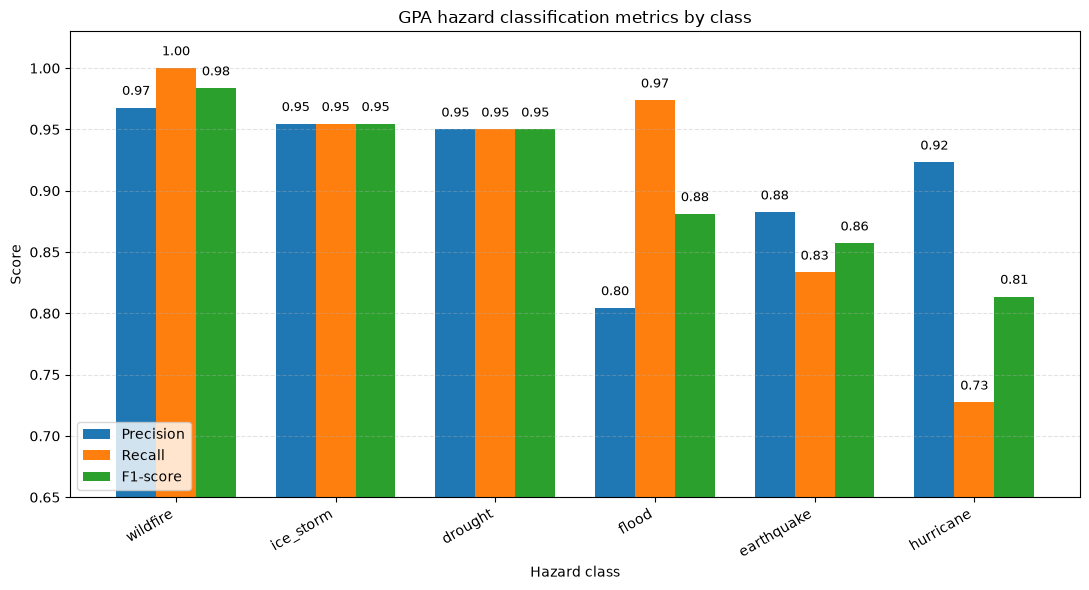

In [8]:
# Improved GPA hazard per-class precision / recall / F1 plot

plot_df = gpa_hazard_classes.copy()
plot_df = plot_df.sort_values("f1", ascending=False)

metrics = ["precision", "recall", "f1"]
labels = ["Precision", "Recall", "F1-score"]

x = np.arange(len(plot_df))
width = 0.25

plt.figure(figsize=(11, 6))

for i, metric in enumerate(metrics):
    bars = plt.bar(
        x + i * width,
        plot_df[metric],
        width,
        label=labels[i],
    )
    
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.008,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=9,
            rotation=0,
        )

plt.xticks(
    x + width,
    plot_df["label"],
    rotation=30,
    ha="right",
)

plt.ylim(0.65, 1.03)
plt.ylabel("Score")
plt.xlabel("Hazard class")
plt.title("GPA hazard classification metrics by class")
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(loc="lower left", frameon=True)

save_fig("gpa_hazard_precision_recall_f1_by_class.png")

### 3.3 Overall Hazard Classification Summary

The overall closed-set hazard classification accuracy is extracted from the summary rows of the metrics file.

The macro and weighted F1-scores summarize performance across all hazard classes.

In [9]:
overall_hazard_accuracy = gpa_hazard_metrics.loc[
    gpa_hazard_metrics["label"] == "OVERALL_HAZARD_ACCURACY",
    "binary_accuracy"
].iloc[0]

macro_f1 = gpa_hazard_metrics.loc[
    gpa_hazard_metrics["label"] == "MACRO_AVERAGE",
    "f1"
].iloc[0]

weighted_f1 = gpa_hazard_metrics.loc[
    gpa_hazard_metrics["label"] == "WEIGHTED_AVERAGE",
    "f1"
].iloc[0]

micro_f1 = gpa_hazard_metrics.loc[
    gpa_hazard_metrics["label"] == "MICRO_AVERAGE",
    "f1"
].iloc[0]

gpa_hazard_summary = pd.DataFrame([
    {"metric": "Overall hazard accuracy", "value": overall_hazard_accuracy},
    {"metric": "Macro F1", "value": macro_f1},
    {"metric": "Weighted F1", "value": weighted_f1},
    {"metric": "Micro F1", "value": micro_f1},
])

gpa_hazard_summary

,metric,value
0,Overall hazard accuracy,0.9095
1,Macro F1,0.9066
2,Weighted F1,0.9081
3,Micro F1,0.9095


Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gpa_hazard_summary_metrics.png


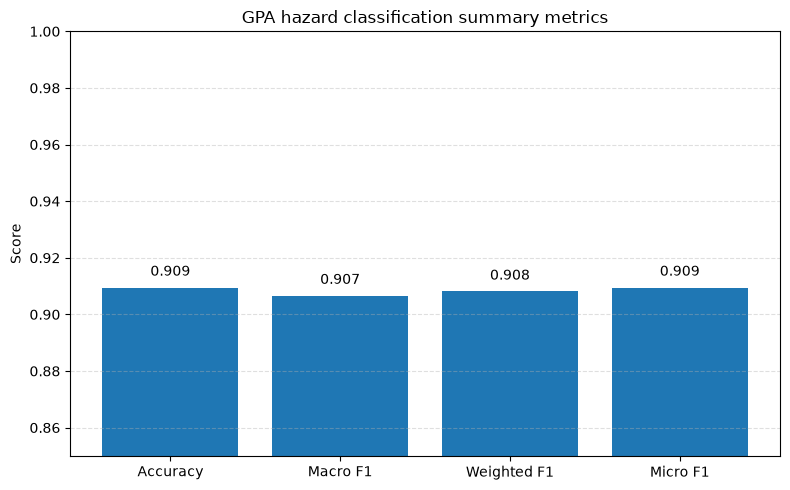

In [10]:
# Improved GPA hazard summary metrics plot

gpa_hazard_summary_plot = gpa_hazard_summary.copy()

gpa_hazard_summary_plot["metric"] = gpa_hazard_summary_plot["metric"].replace({
    "Overall hazard accuracy": "Accuracy",
    "Macro F1": "Macro F1",
    "Weighted F1": "Weighted F1",
    "Micro F1": "Micro F1",
})

plt.figure(figsize=(8, 5))

bars = plt.bar(
    gpa_hazard_summary_plot["metric"],
    gpa_hazard_summary_plot["value"],
)

plt.ylim(0.85, 1.00)
plt.ylabel("Score")
plt.xlabel("")
plt.title("GPA hazard classification summary metrics")
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.003,
        f"{height:.3f}",
        ha="center",
        va="bottom",
        fontsize=10,
    )

save_fig("gpa_hazard_summary_metrics.png")

### 3.4 Hazard Classification Confusion Matrix

The confusion matrix shows where the GeoPerception Agent confused one hazard category with another.

This figure is useful for identifying systematic class-level errors, such as confusion between visually similar disaster types.

In [11]:
gpa_hazard_cm = load_confusion_matrix(
    "evaluation/hermes_gpa_hazard_full_neutral_confusion_matrix_closedset.csv"
)

gpa_hazard_cm

,drought,earthquake,flood,hurricane,ice_storm,wildfire
gt_label,,,,,,
drought,38,2,0,0,0,0
earthquake,0,30,3,2,0,1
flood,0,0,37,0,1,0
hurricane,0,2,6,24,1,0
ice_storm,2,0,0,0,42,0
wildfire,0,0,0,0,0,30


Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gpa_hazard_confusion_matrix.png


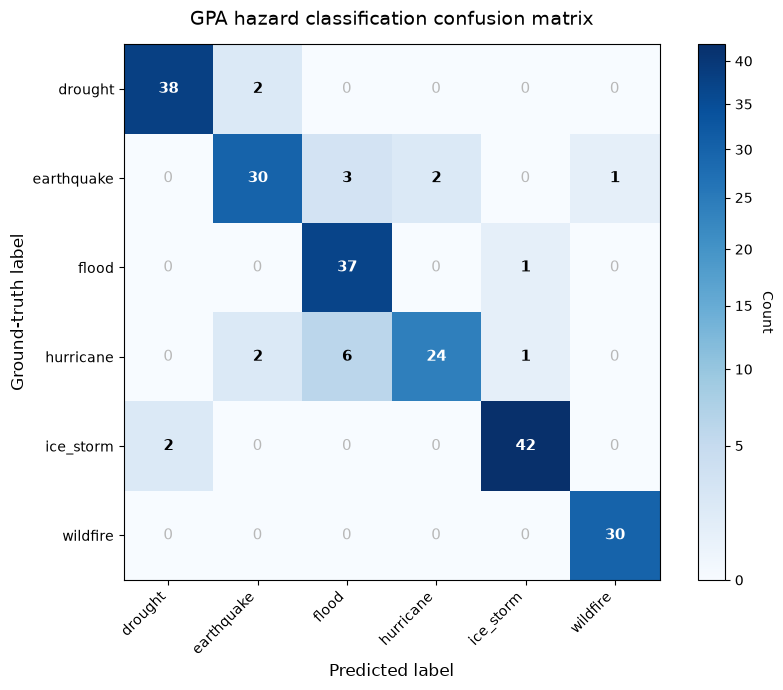

In [12]:
plot_confusion_matrix(
    gpa_hazard_cm,
    title="GPA hazard classification confusion matrix",
    filename="gpa_hazard_confusion_matrix.png",
    show_zeros=True,
)

### 3.5 Interpretation of Hazard Classification Results

The GeoPerception Agent achieved strong overall performance in the closed-set hazard classification task. Overall hazard accuracy, macro F1-score, weighted F1-score, and micro F1-score were all close to 0.91, indicating stable performance across the evaluated hazard categories.

At the class level, wildfire, ice storm, and drought achieved the strongest F1-scores. Hurricane and earthquake were comparatively more challenging, mainly due to lower recall. Flood achieved high recall but lower precision, indicating that some non-flood cases were incorrectly classified as flood. The confusion matrix confirms that most predictions lie on the diagonal, while the main errors occur between visually related or ambiguous disaster classes.

## 4. Evaluation 2 — GeoPerception Agent Input-Mode Recognition

This evaluation assesses whether the GeoPerception Agent correctly identifies the input evidence configuration of each case.

Input-mode recognition is important because it determines the downstream processing route used by HERMES. For example, a case with paired street-view and remote-sensing imagery should be routed differently from a bi-temporal street-view case or a single post-disaster street-view image.

The main outputs visualized in this section are:

- Overall input-mode recognition performance
- Input-mode confusion matrix
- Accuracy by scenario
- Ground-truth versus predicted input-mode distribution

In [13]:
gpa_mode_metrics = load_csv(
    "evaluation/hermes_gpa_mode_full_neutral_metrics.csv"
)

gpa_mode_metrics = clean_columns(gpa_mode_metrics)

print("GPA mode metrics shape:", gpa_mode_metrics.shape)
print("Columns:")
print(gpa_mode_metrics.columns.tolist())

gpa_mode_metrics

GPA mode metrics shape: (9, 10)
Columns:
['mode', 'precision', 'recall', 'f1', 'binary_accuracy', 'tp', 'fp', 'fn', 'tn', 'support']


,mode,precision,recall,f1,binary_accuracy,tp,fp,fn,tn,support
0,post_sv_single,1.0000,0.9729,0.9862,0.9828,502.0,0.0,14.0,300.0,516
1,post_rs_single,0.0000,0.0000,0.0000,0.9853,0.0,12.0,0.0,804.0,0
2,post_paired_sv_rs,1.0000,1.0000,1.0000,1.0000,150.0,0.0,0.0,666.0,150
3,bitemporal_sv,0.9868,1.0000,0.9934,0.9975,150.0,2.0,0.0,664.0,150
4,bitemporal_rs,0.0000,0.0000,0.0000,1.0000,0.0,0.0,0.0,816.0,0
5,MACRO_AVERAGE,0.5974,0.5946,0.5959,NaN,NaN,NaN,NaN,NaN,816
6,WEIGHTED_AVERAGE,0.9976,0.9829,0.9901,NaN,NaN,NaN,NaN,NaN,816
7,MICRO_AVERAGE,0.9828,0.9828,0.9828,NaN,802.0,14.0,14.0,NaN,816
8,OVERALL_MODE_ACCURACY,NaN,NaN,NaN,0.9828,802.0,14.0,NaN,NaN,816


In [14]:
# Keep only input modes that appear as ground truth in the evaluation set.
# Modes with support = 0 are valid label-space entries, but they are not active ground-truth classes here.

gpa_mode_active = gpa_mode_metrics[
    gpa_mode_metrics["support"] > 0
].copy()

# Remove aggregate rows.
gpa_mode_active = gpa_mode_active[
    ~gpa_mode_active["mode"].isin([
        "MACRO_AVERAGE",
        "WEIGHTED_AVERAGE",
        "MICRO_AVERAGE",
        "OVERALL_MODE_ACCURACY",
    ])
].copy()

gpa_mode_active = coerce_numeric(
    gpa_mode_active,
    ["precision", "recall", "f1", "binary_accuracy", "support"]
)

gpa_mode_active

,mode,precision,recall,f1,binary_accuracy,tp,fp,fn,tn,support
0,post_sv_single,1.0000,0.9729,0.9862,0.9828,502.0,0.0,14.0,300.0,516
2,post_paired_sv_rs,1.0000,1.0000,1.0000,1.0000,150.0,0.0,0.0,666.0,150
3,bitemporal_sv,0.9868,1.0000,0.9934,0.9975,150.0,2.0,0.0,664.0,150


### 4.1 Per-Mode Recognition Metrics

The following chart compares precision, recall, and F1-score for the active input modes in the evaluation set.

Modes with zero ground-truth support are excluded from this chart, because their recall and F1-scores are not meaningful in this dataset. They remain visible in the confusion matrix and in the full metrics table.

Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gpa_mode_precision_recall_f1_by_active_mode.png


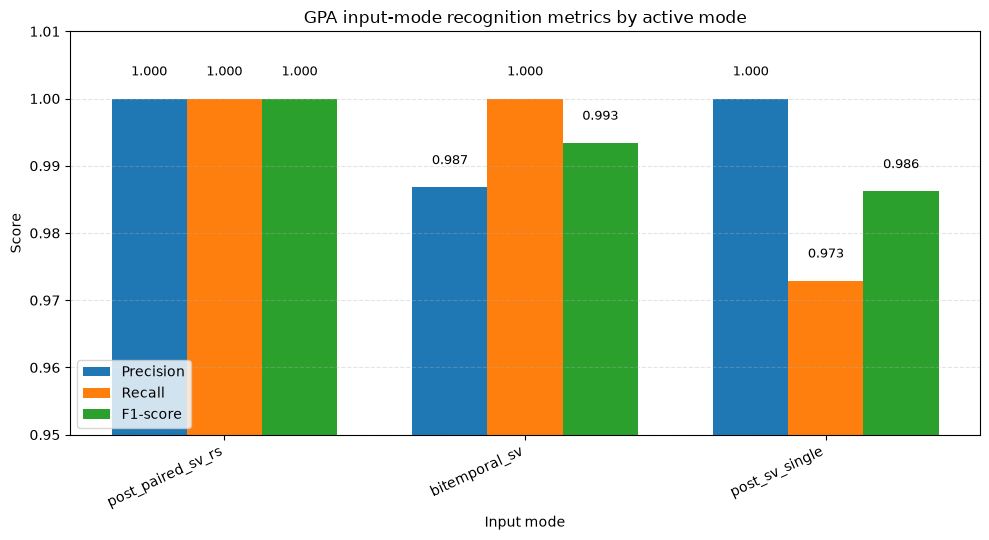

In [15]:
# Improved GPA input-mode precision / recall / F1 plot

plot_df = gpa_mode_active.copy()
plot_df = plot_df.sort_values("f1", ascending=False)

metrics = ["precision", "recall", "f1"]
labels = ["Precision", "Recall", "F1-score"]

x = np.arange(len(plot_df))
width = 0.25

plt.figure(figsize=(10, 5.5))

for i, metric in enumerate(metrics):
    bars = plt.bar(
        x + i * width,
        plot_df[metric],
        width,
        label=labels[i],
    )
    
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.003,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

plt.xticks(
    x + width,
    plot_df["mode"],
    rotation=25,
    ha="right",
)

plt.ylim(0.95, 1.01)
plt.ylabel("Score")
plt.xlabel("Input mode")
plt.title("GPA input-mode recognition metrics by active mode")
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(loc="lower left", frameon=True)

save_fig("gpa_mode_precision_recall_f1_by_active_mode.png")

### 4.2 Overall Input-Mode Recognition Summary

The overall input-mode accuracy summarizes whether the GeoPerception Agent selected the correct evidence configuration across the full benchmark.

The weighted and micro F1-scores are more informative than the macro F1-score in this case, because the full label space includes modes with zero ground-truth support.

In [16]:
overall_mode_accuracy = gpa_mode_metrics.loc[
    gpa_mode_metrics["mode"] == "OVERALL_MODE_ACCURACY",
    "binary_accuracy"
].iloc[0]

weighted_mode_f1 = gpa_mode_metrics.loc[
    gpa_mode_metrics["mode"] == "WEIGHTED_AVERAGE",
    "f1"
].iloc[0]

micro_mode_f1 = gpa_mode_metrics.loc[
    gpa_mode_metrics["mode"] == "MICRO_AVERAGE",
    "f1"
].iloc[0]

gpa_mode_summary = pd.DataFrame([
    {"metric": "Accuracy", "value": overall_mode_accuracy},
    {"metric": "Weighted F1", "value": weighted_mode_f1},
    {"metric": "Micro F1", "value": micro_mode_f1},
])

gpa_mode_summary

,metric,value
0,Accuracy,0.9828
1,Weighted F1,0.9901
2,Micro F1,0.9828


Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gpa_mode_summary_metrics.png


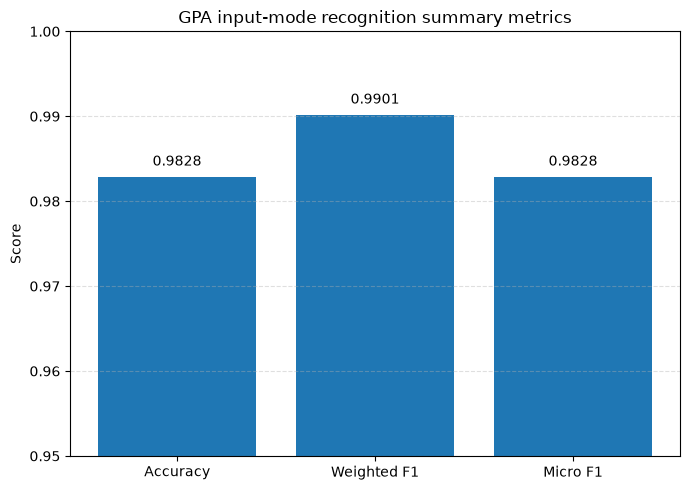

In [17]:
plt.figure(figsize=(7, 5))

bars = plt.bar(
    gpa_mode_summary["metric"],
    gpa_mode_summary["value"],
)

plt.ylim(0.95, 1.00)
plt.ylabel("Score")
plt.xlabel("")
plt.title("GPA input-mode recognition summary metrics")
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.001,
        f"{height:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
    )

save_fig("gpa_mode_summary_metrics.png")

### 4.3 Input-Mode Confusion Matrix

The confusion matrix shows how ground-truth input modes were classified by the GeoPerception Agent.

This figure is important for identifying routing errors, because incorrect input-mode recognition may send a case to the wrong downstream analysis workflow.

In [18]:
gpa_mode_cm = load_confusion_matrix(
    "evaluation/hermes_gpa_mode_full_neutral_confusion_matrix.csv"
)

gpa_mode_cm

,post_sv_single,post_rs_single,post_paired_sv_rs,bitemporal_sv,bitemporal_rs
gt_mode,,,,,
post_sv_single,502,12,0,2,0
post_rs_single,0,0,0,0,0
post_paired_sv_rs,0,0,150,0,0
bitemporal_sv,0,0,0,150,0
bitemporal_rs,0,0,0,0,0


Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gpa_mode_confusion_matrix.png


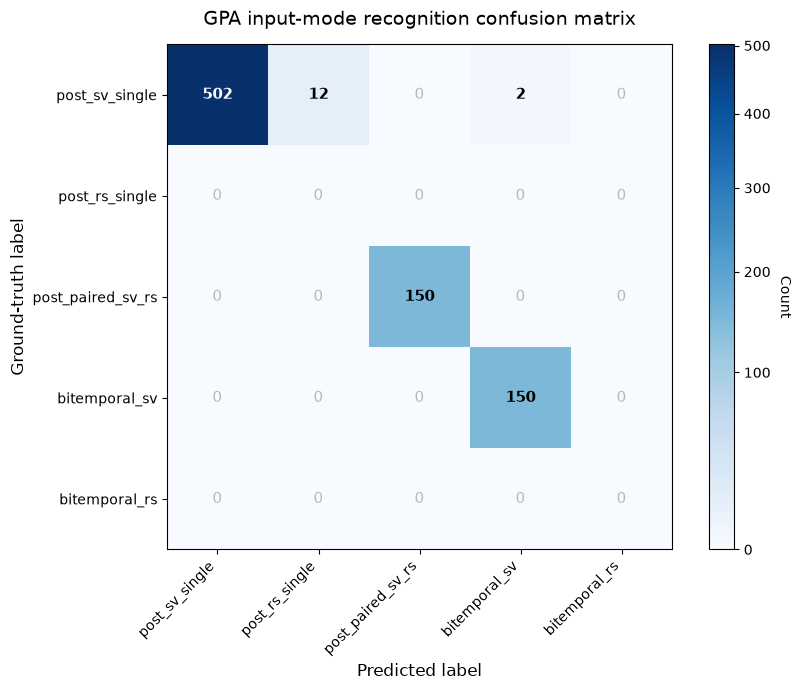

In [19]:
plot_confusion_matrix(
    gpa_mode_cm,
    title="GPA input-mode recognition confusion matrix",
    filename="gpa_mode_confusion_matrix.png",
    show_zeros=True,
)

### 4.4 Input-Mode Accuracy by Scenario

The following table and chart summarize input-mode recognition accuracy by HERMES scenario.

This is useful because different scenarios correspond to different evidence configurations, such as cross-view SVI–RSI pairs, bi-temporal street-view pairs, or single post-disaster street-view images.

In [20]:
gpa_mode_by_scenario = load_csv(
    "evaluation/hermes_gpa_mode_full_neutral_by_scenario.csv"
)

gpa_mode_by_scenario = clean_columns(gpa_mode_by_scenario)

print("GPA mode by-scenario shape:", gpa_mode_by_scenario.shape)
print("Columns:")
print(gpa_mode_by_scenario.columns.tolist())

gpa_mode_by_scenario

GPA mode by-scenario shape: (4, 6)
Columns:
['scenario', 'cases', 'correct', 'accuracy', 'gt_modes', 'pred_modes']


,scenario,cases,correct,accuracy,gt_modes,pred_modes
0,cross_view_svi_rsi,150,150,1.0000,post_paired_sv_rs,post_paired_sv_rs
1,pre_post_svi,150,150,1.0000,bitemporal_sv,bitemporal_sv
2,single_svi_hazard_classification,221,208,0.9412,post_sv_single,bitemporal_sv;post_rs_single;post_sv_single
3,wildfire_building,295,294,0.9966,post_sv_single,post_rs_single;post_sv_single


Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gpa_mode_accuracy_by_scenario.png


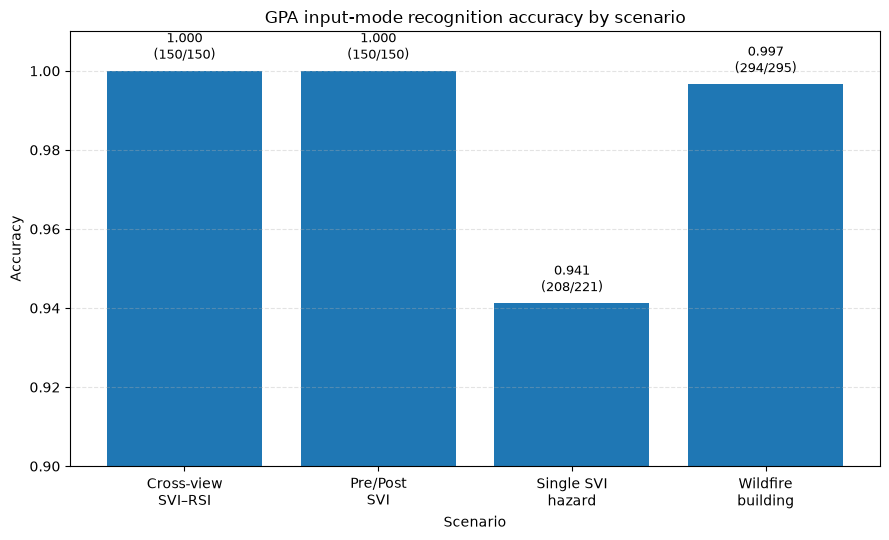

In [21]:
# Plot GPA input-mode recognition accuracy by scenario

gpa_mode_by_scenario_plot = gpa_mode_by_scenario.copy()

# Shorter labels for cleaner thesis figures
scenario_label_map = {
    "cross_view_svi_rsi": "Cross-view\nSVI–RSI",
    "pre_post_svi": "Pre/Post\nSVI",
    "single_svi_hazard_classification": "Single SVI\nhazard",
    "wildfire_building": "Wildfire\nbuilding",
}

gpa_mode_by_scenario_plot["scenario_label"] = (
    gpa_mode_by_scenario_plot["scenario"]
    .map(scenario_label_map)
    .fillna(gpa_mode_by_scenario_plot["scenario"])
)

gpa_mode_by_scenario_plot = coerce_numeric(
    gpa_mode_by_scenario_plot,
    ["cases", "correct", "accuracy"]
)

plt.figure(figsize=(9, 5.5))

bars = plt.bar(
    gpa_mode_by_scenario_plot["scenario_label"],
    gpa_mode_by_scenario_plot["accuracy"],
)

plt.ylim(0.90, 1.01)
plt.ylabel("Accuracy")
plt.xlabel("Scenario")
plt.title("GPA input-mode recognition accuracy by scenario")
plt.grid(axis="y", linestyle="--", alpha=0.35)

for bar, accuracy, correct, cases in zip(
    bars,
    gpa_mode_by_scenario_plot["accuracy"],
    gpa_mode_by_scenario_plot["correct"],
    gpa_mode_by_scenario_plot["cases"],
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 0.002,
        f"{accuracy:.3f}\n({int(correct)}/{int(cases)})",
        ha="center",
        va="bottom",
        fontsize=9,
    )

save_fig("gpa_mode_accuracy_by_scenario.png")

### 4.5 Interpretation of Input-Mode Recognition Results

The GeoPerception Agent achieved very strong input-mode recognition performance across the full benchmark. Overall input-mode accuracy reached 0.9828, with 802 correctly classified cases out of 816.

The agent correctly recognized all cross-view SVI–RSI cases and all pre/post SVI cases. The wildfire-building scenario also achieved near-perfect performance, with only one error across 295 cases. Most input-mode errors occurred in the single-SVI hazard-classification scenario, where some single post-disaster street-view images were misclassified as either remote-sensing or bi-temporal inputs.

This result indicates that the GeoPerception Agent provides a reliable routing signal for downstream HERMES workflows.

### 4.6 Figure Captions for Thesis

**Figure X. GPA input-mode recognition metrics by active mode.**  
Per-mode precision, recall, and F1-score for the active input modes in the HERMES benchmark. Modes with zero ground-truth support are excluded from this figure.

**Figure X. GPA input-mode recognition confusion matrix.**  
Confusion matrix for input-mode recognition. Rows correspond to ground-truth input modes and columns to predicted modes. The matrix shows that cross-view SVI–RSI and pre/post SVI cases were perfectly routed, while remaining errors occurred primarily in single-image SVI cases.

**Figure X. GPA input-mode recognition accuracy by scenario.**  
Scenario-level input-mode recognition accuracy. The GeoPerception Agent achieved perfect accuracy for cross-view SVI–RSI and pre/post SVI cases, near-perfect accuracy for wildfire-building cases, and lower but still strong performance for single-SVI hazard-classification cases.

In [22]:
gpa_mode_summary_table = pd.DataFrame([
    {
        "metric": "Overall input-mode accuracy",
        "value": overall_mode_accuracy,
    },
    {
        "metric": "Weighted F1",
        "value": weighted_mode_f1,
    },
    {
        "metric": "Micro F1",
        "value": micro_mode_f1,
    },
    {
        "metric": "Correct cases",
        "value": int(
            gpa_mode_metrics.loc[
                gpa_mode_metrics["mode"] == "OVERALL_MODE_ACCURACY",
                "tp"
            ].iloc[0]
        ),
    },
    {
        "metric": "Total cases",
        "value": int(
            gpa_mode_metrics.loc[
                gpa_mode_metrics["mode"] == "OVERALL_MODE_ACCURACY",
                "support"
            ].iloc[0]
        ),
    },
])

gpa_mode_summary_table

,metric,value
0,Overall input-mode accuracy,0.9828
1,Weighted F1,0.9901
2,Micro F1,0.9828
3,Correct cases,802.0000
4,Total cases,816.0000


## 5. Evaluation 3 — GeoDamageAnalysis Agent Severity Evaluation

This evaluation assesses the ability of the GeoDamageAnalysis Agent to estimate disaster damage severity.

Severity estimation is treated as an ordinal classification task. Therefore, performance is evaluated using both exact severity accuracy and the Normalized Cross-Severity Error (NCSE).

Exact accuracy measures whether the predicted severity class exactly matches the ground-truth class. NCSE complements exact accuracy by accounting for the ordinal distance between the predicted and reference severity levels. Lower NCSE values indicate that misclassifications are closer to the correct severity class.

The evaluated scenarios are:

- Cross-view SVI–RSI damage assessment
- Pre/post SVI damage assessment
- Wildfire building-damage classification

In [23]:
gdaa_severity_by_scenario = load_csv(
    "evaluation/hermes_gdaa_severity_full_by_scenario.csv"
)

gdaa_severity_by_scenario = clean_columns(gdaa_severity_by_scenario)

print("GDAA severity by-scenario shape:", gdaa_severity_by_scenario.shape)
print("Columns:")
print(gdaa_severity_by_scenario.columns.tolist())

gdaa_severity_by_scenario

GDAA severity by-scenario shape: (3, 5)
Columns:
['scenario', 'total', 'correct', 'accuracy', 'mean_ncse']


,scenario,total,correct,accuracy,mean_ncse
0,cross_view_svi_rsi,150,41,0.273333,0.386667
1,pre_post_svi,150,68,0.453333,0.320000
2,wildfire_building,295,169,0.572881,0.175424


In [24]:
# Prepare scenario labels for cleaner plotting

gdaa_severity_by_scenario_plot = gdaa_severity_by_scenario.copy()

scenario_label_map = {
    "cross_view_svi_rsi": "Cross-view\nSVI–RSI",
    "pre_post_svi": "Pre/Post\nSVI",
    "wildfire_building": "Wildfire\nbuilding",
}

gdaa_severity_by_scenario_plot["scenario_label"] = (
    gdaa_severity_by_scenario_plot["scenario"]
    .map(scenario_label_map)
    .fillna(gdaa_severity_by_scenario_plot["scenario"])
)

gdaa_severity_by_scenario_plot = coerce_numeric(
    gdaa_severity_by_scenario_plot,
    ["total", "correct", "accuracy", "mean_ncse"]
)

gdaa_severity_by_scenario_plot

,scenario,total,correct,accuracy,mean_ncse,scenario_label
0,cross_view_svi_rsi,150,41,0.273333,0.386667,Cross-view\nSVI–RSI
1,pre_post_svi,150,68,0.453333,0.320000,Pre/Post\nSVI
2,wildfire_building,295,169,0.572881,0.175424,Wildfire\nbuilding


### 5.1 Severity Accuracy by Scenario

The following chart shows exact severity-classification accuracy by scenario.

Exact accuracy is strict: a prediction is counted as correct only when the predicted severity label exactly matches the ground-truth label.

Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gdaa_severity_accuracy_by_scenario.png


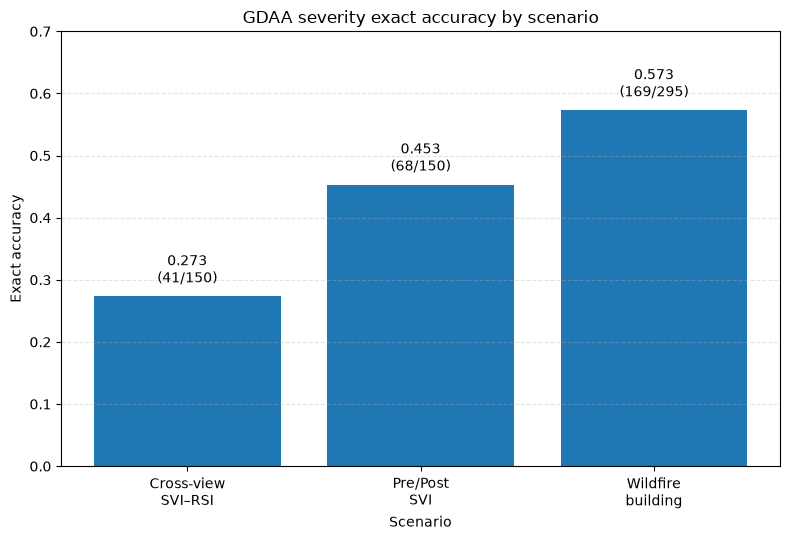

In [25]:
plt.figure(figsize=(8, 5.5))

bars = plt.bar(
    gdaa_severity_by_scenario_plot["scenario_label"],
    gdaa_severity_by_scenario_plot["accuracy"],
)

plt.ylim(0, 0.70)
plt.ylabel("Exact accuracy")
plt.xlabel("Scenario")
plt.title("GDAA severity exact accuracy by scenario")
plt.grid(axis="y", linestyle="--", alpha=0.35)

for bar, accuracy, correct, total in zip(
    bars,
    gdaa_severity_by_scenario_plot["accuracy"],
    gdaa_severity_by_scenario_plot["correct"],
    gdaa_severity_by_scenario_plot["total"],
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 0.015,
        f"{accuracy:.3f}\n({int(correct)}/{int(total)})",
        ha="center",
        va="bottom",
        fontsize=10,
    )

save_fig("gdaa_severity_accuracy_by_scenario.png")

### 5.2 Mean NCSE by Scenario

The following chart shows the mean Normalized Cross-Severity Error (NCSE) by scenario.

Unlike exact accuracy, NCSE accounts for the ordinal distance between predicted and ground-truth severity labels. Lower NCSE values indicate that prediction errors are closer to the correct severity class.

Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gdaa_severity_ncse_by_scenario.png


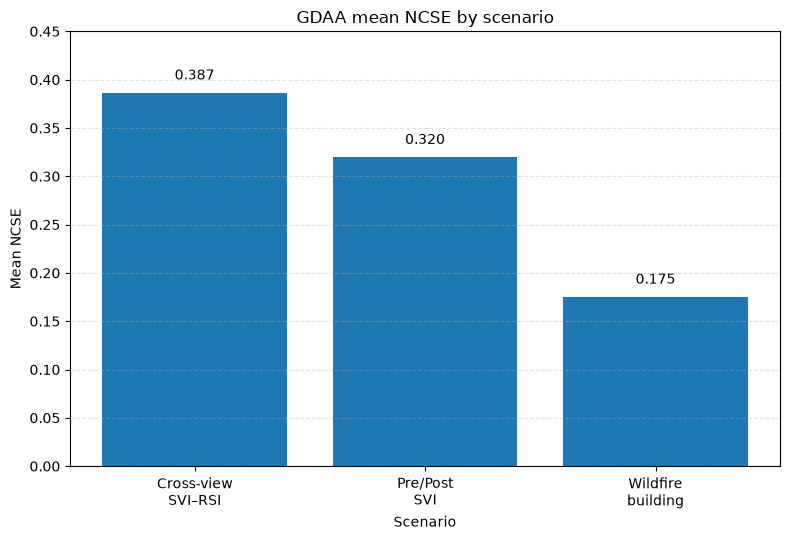

In [26]:
plt.figure(figsize=(8, 5.5))

bars = plt.bar(
    gdaa_severity_by_scenario_plot["scenario_label"],
    gdaa_severity_by_scenario_plot["mean_ncse"],
)

plt.ylim(0, 0.45)
plt.ylabel("Mean NCSE")
plt.xlabel("Scenario")
plt.title("GDAA mean NCSE by scenario")
plt.grid(axis="y", linestyle="--", alpha=0.35)

for bar, ncse in zip(
    bars,
    gdaa_severity_by_scenario_plot["mean_ncse"],
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        ncse + 0.01,
        f"{ncse:.3f}",
        ha="center",
        va="bottom",
        fontsize=10,
    )

save_fig("gdaa_severity_ncse_by_scenario.png")

### 5.3 Accuracy and NCSE Comparison

The following chart compares exact accuracy and mean NCSE across severity-evaluation scenarios.

A strong scenario should ideally have high exact accuracy and low NCSE. The wildfire-building scenario shows the best overall severity performance, while cross-view SVI–RSI is the most challenging setting.

Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gdaa_severity_accuracy_ncse_by_scenario.png


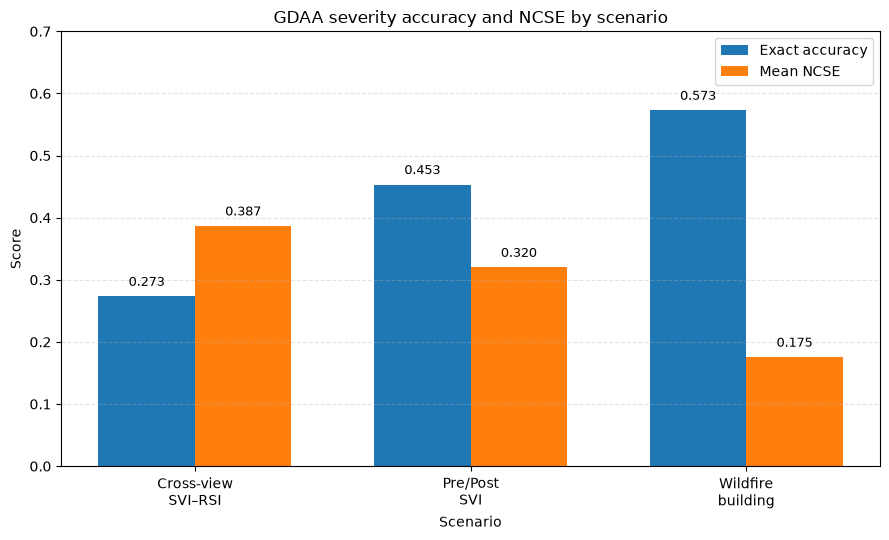

In [27]:
comparison_df = gdaa_severity_by_scenario_plot.copy()

x = np.arange(len(comparison_df))
width = 0.35

plt.figure(figsize=(9, 5.5))

bars_acc = plt.bar(
    x - width / 2,
    comparison_df["accuracy"],
    width,
    label="Exact accuracy",
)

bars_ncse = plt.bar(
    x + width / 2,
    comparison_df["mean_ncse"],
    width,
    label="Mean NCSE",
)

plt.xticks(
    x,
    comparison_df["scenario_label"],
)

plt.ylim(0, 0.70)
plt.ylabel("Score")
plt.xlabel("Scenario")
plt.title("GDAA severity accuracy and NCSE by scenario")
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(frameon=True)

for bars in [bars_acc, bars_ncse]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.012,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

save_fig("gdaa_severity_accuracy_ncse_by_scenario.png")

### 5.4 Interpretation of Severity Evaluation by Scenario

The GeoDamageAnalysis Agent achieved its strongest severity-estimation performance in the wildfire-building scenario, with an exact accuracy of 0.5729 and the lowest mean NCSE of 0.1754. This indicates that even when exact class predictions were incorrect, errors were relatively close to the correct ordinal severity level.

The pre/post SVI scenario achieved moderate performance, with an exact accuracy of 0.4533 and a mean NCSE of 0.3200. The cross-view SVI–RSI scenario was the most challenging setting, with an exact accuracy of 0.2733 and the highest mean NCSE of 0.3867. This suggests that fusing remote-sensing and street-view evidence for fine-grained ordinal damage assessment remains difficult.

Overall, the severity-evaluation results show that ordinal damage classification is substantially more challenging than hazard recognition or input-mode recognition.

## 5.5 GDAA Severity Per-Class Metrics and Confusion Matrix

In this section, I analyze the per-class performance of the GeoDamageAnalysis Agent for severity estimation.

Beyond scenario-level accuracy and NCSE, per-class precision, recall, and F1-score provide a more detailed view of how the model behaves for each severity level. I also inspect the confusion matrix in order to identify the most common severity confusions.

In [28]:
gdaa_severity_metrics = pd.read_csv(
    EVAL_DIR / "hermes_gdaa_severity_full_metrics.csv"
)

gdaa_severity_confusion = pd.read_csv(
    EVAL_DIR / "hermes_gdaa_severity_full_confusion_matrix.csv"
)

print("GDAA severity metrics shape:", gdaa_severity_metrics.shape)
print("Columns:")
print(gdaa_severity_metrics.columns.tolist())
print()
display(gdaa_severity_metrics.head(15))

print("GDAA severity confusion matrix shape:", gdaa_severity_confusion.shape)
print("Columns:")
print(gdaa_severity_confusion.columns.tolist())
print()
display(gdaa_severity_confusion.head(15))

GDAA severity metrics shape: (11, 12)
Columns:
['scenario', 'label_id', 'label', 'support', 'tp', 'fp', 'fn', 'tn', 'precision', 'recall', 'f1', 'binary_accuracy']



,scenario,label_id,label,support,tp,fp,fn,tn,precision,recall,f1,binary_accuracy
0,cross_view_svi_rsi,0,Mild,50,3,0,47,100,1.000000,0.060000,0.113208,0.686667
1,cross_view_svi_rsi,1,Moderate,50,19,71,31,29,0.211111,0.380000,0.271429,0.320000
2,cross_view_svi_rsi,2,Severe,50,19,38,31,62,0.333333,0.380000,0.355140,0.540000
3,pre_post_svi,0,Mild,50,5,2,45,98,0.714286,0.100000,0.175439,0.686667
4,pre_post_svi,1,Moderate,50,28,46,22,54,0.378378,0.560000,0.451613,0.546667
5,pre_post_svi,2,Severe,50,35,34,15,66,0.507246,0.700000,0.588235,0.673333
6,wildfire_building,0,0_No_Damage,60,60,70,0,165,0.461538,1.000000,0.631579,0.762712
7,wildfire_building,1,1_Affected_1_9,58,8,7,50,230,0.533333,0.137931,0.219178,0.806780
8,wildfire_building,2,2_Minor_10_25,60,24,23,36,212,0.510638,0.400000,0.448598,0.800000
9,wildfire_building,3,3_Major_26_50,57,21,16,36,222,0.567568,0.368421,0.446809,0.823729


GDAA severity confusion matrix shape: (11, 8)
Columns:
['scenario', 'gt_id', 'gt_label', 'pred_0', 'pred_1', 'pred_2', 'pred_3', 'pred_4']



,scenario,gt_id,gt_label,pred_0,pred_1,pred_2,pred_3,pred_4
0,cross_view_svi_rsi,0,Mild,3,40,7,NaN,NaN
1,cross_view_svi_rsi,1,Moderate,0,19,31,NaN,NaN
2,cross_view_svi_rsi,2,Severe,0,31,19,NaN,NaN
3,pre_post_svi,0,Mild,5,31,14,NaN,NaN
4,pre_post_svi,1,Moderate,2,28,20,NaN,NaN
5,pre_post_svi,2,Severe,0,15,35,NaN,NaN
6,wildfire_building,0,0_No_Damage,60,0,0,0.0,0.0
7,wildfire_building,1,1_Affected_1_9,28,8,16,4.0,2.0
8,wildfire_building,2,2_Minor_10_25,19,4,24,11.0,2.0
9,wildfire_building,3,3_Major_26_50,21,2,7,21.0,6.0


The following outputs are used to inspect the structure of the severity metrics and confusion-matrix files before plotting. This step ensures that the notebook uses the correct columns and filtering logic.

In [29]:
gdaa_severity_metrics_plot = gdaa_severity_metrics.copy()

# Keep only real class rows, not macro/weighted/overall summary rows
exclude_labels = {
    "MACRO_AVERAGE",
    "WEIGHTED_AVERAGE",
    "MICRO_AVERAGE",
    "OVERALL_ACCURACY",
    "OVERALL_SEVERITY_ACCURACY",
    "MEAN_NCSE",
}

if "label" in gdaa_severity_metrics_plot.columns:
    gdaa_severity_metrics_plot = gdaa_severity_metrics_plot[
        ~gdaa_severity_metrics_plot["label"].astype(str).isin(exclude_labels)
    ].copy()

numeric_cols = ["precision", "recall", "f1", "support", "tp", "fp", "fn"]
existing_numeric_cols = [c for c in numeric_cols if c in gdaa_severity_metrics_plot.columns]
gdaa_severity_metrics_plot = coerce_numeric(gdaa_severity_metrics_plot, existing_numeric_cols)

print("Filtered per-class severity metrics shape:", gdaa_severity_metrics_plot.shape)
display(gdaa_severity_metrics_plot.head(20))

Filtered per-class severity metrics shape: (11, 12)


,scenario,label_id,label,support,tp,fp,fn,tn,precision,recall,f1,binary_accuracy
0,cross_view_svi_rsi,0,Mild,50,3,0,47,100,1.000000,0.060000,0.113208,0.686667
1,cross_view_svi_rsi,1,Moderate,50,19,71,31,29,0.211111,0.380000,0.271429,0.320000
2,cross_view_svi_rsi,2,Severe,50,19,38,31,62,0.333333,0.380000,0.355140,0.540000
3,pre_post_svi,0,Mild,50,5,2,45,98,0.714286,0.100000,0.175439,0.686667
4,pre_post_svi,1,Moderate,50,28,46,22,54,0.378378,0.560000,0.451613,0.546667
5,pre_post_svi,2,Severe,50,35,34,15,66,0.507246,0.700000,0.588235,0.673333
6,wildfire_building,0,0_No_Damage,60,60,70,0,165,0.461538,1.000000,0.631579,0.762712
7,wildfire_building,1,1_Affected_1_9,58,8,7,50,230,0.533333,0.137931,0.219178,0.806780
8,wildfire_building,2,2_Minor_10_25,60,24,23,36,212,0.510638,0.400000,0.448598,0.800000
9,wildfire_building,3,3_Major_26_50,57,21,16,36,222,0.567568,0.368421,0.446809,0.823729


The filtered table contains the class-level severity metrics used in the following plots.

In [30]:
if "scenario" in gdaa_severity_metrics_plot.columns:
    print("Scenarios:")
    print(sorted(gdaa_severity_metrics_plot["scenario"].dropna().unique().tolist()))
    print()

if "label" in gdaa_severity_metrics_plot.columns:
    print("Severity labels:")
    print(sorted(gdaa_severity_metrics_plot["label"].dropna().unique().tolist()))

Scenarios:
['cross_view_svi_rsi', 'pre_post_svi', 'wildfire_building']

Severity labels:
['0_No_Damage', '1_Affected_1_9', '2_Minor_10_25', '3_Major_26_50', '4_Destroyed_50plus', 'Mild', 'Moderate', 'Severe']


Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gdaa_severity_f1_by_class_cross_view_svi_rsi.png


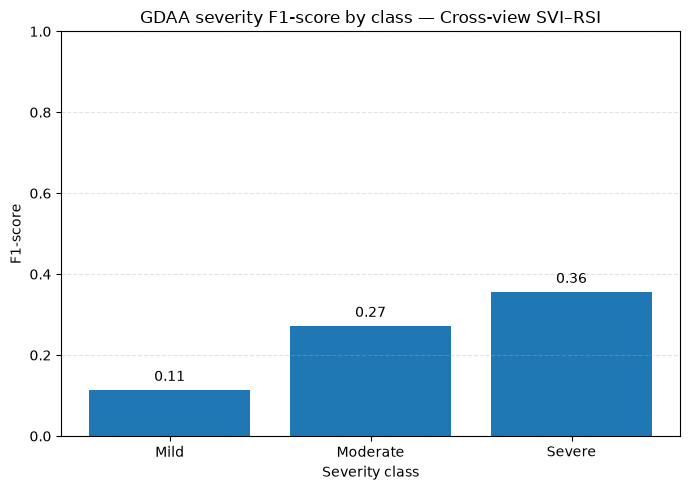

In [31]:
# Per-class F1-score for cross-view SVI–RSI severity evaluation

scenario = "cross_view_svi_rsi"
scenario_label = "Cross-view SVI–RSI"

plot_df = (
    gdaa_severity_metrics_plot[
        gdaa_severity_metrics_plot["scenario"] == scenario
    ]
    .sort_values("label_id")
    .copy()
)

plt.figure(figsize=(7, 5))

bars = plt.bar(
    plot_df["label"],
    plot_df["f1"],
)

plt.ylim(0, 1.0)
plt.ylabel("F1-score")
plt.xlabel("Severity class")
plt.title(f"GDAA severity F1-score by class — {scenario_label}")
plt.grid(axis="y", linestyle="--", alpha=0.35)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.015,
        f"{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=10,
    )

save_fig("gdaa_severity_f1_by_class_cross_view_svi_rsi.png")

Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gdaa_severity_precision_recall_f1_cross_view_svi_rsi.png


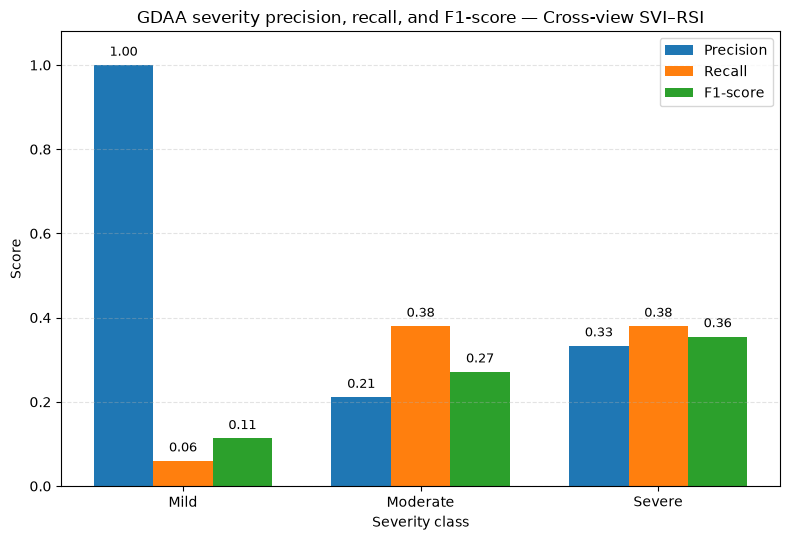

In [32]:
# Precision, recall, and F1-score for cross-view SVI–RSI severity evaluation

scenario = "cross_view_svi_rsi"
scenario_label = "Cross-view SVI–RSI"

plot_df = (
    gdaa_severity_metrics_plot[
        gdaa_severity_metrics_plot["scenario"] == scenario
    ]
    .sort_values("label_id")
    .copy()
)

metrics = ["precision", "recall", "f1"]
metric_labels = ["Precision", "Recall", "F1-score"]

x = np.arange(len(plot_df))
width = 0.25

plt.figure(figsize=(8, 5.5))

for i, metric in enumerate(metrics):
    bars = plt.bar(
        x + i * width,
        plot_df[metric],
        width,
        label=metric_labels[i],
    )

    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.015,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

plt.xticks(
    x + width,
    plot_df["label"],
)

plt.ylim(0, 1.08)
plt.ylabel("Score")
plt.xlabel("Severity class")
plt.title(f"GDAA severity precision, recall, and F1-score — {scenario_label}")
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(frameon=True)

save_fig("gdaa_severity_precision_recall_f1_cross_view_svi_rsi.png")

Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gdaa_severity_precision_recall_f1_pre_post_svi.png


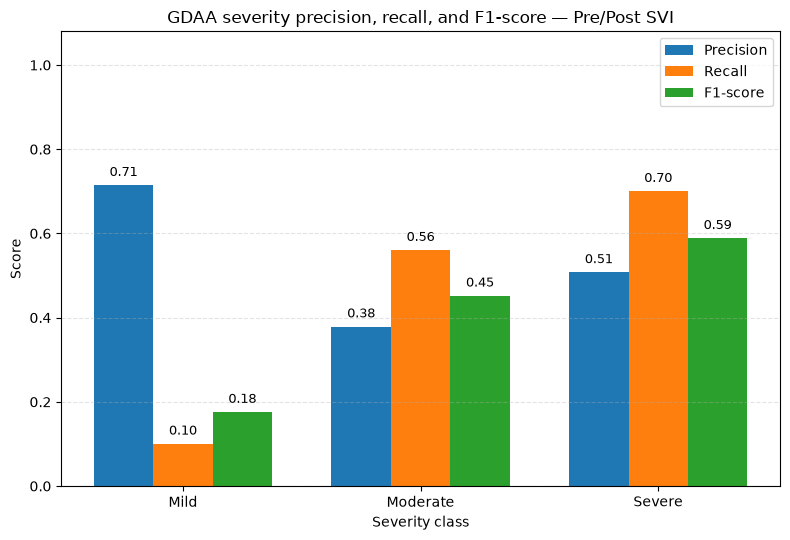

In [33]:
# Precision, recall, and F1-score for pre/post SVI severity evaluation

scenario = "pre_post_svi"
scenario_label = "Pre/Post SVI"

plot_df = (
    gdaa_severity_metrics_plot[
        gdaa_severity_metrics_plot["scenario"] == scenario
    ]
    .sort_values("label_id")
    .copy()
)

metrics = ["precision", "recall", "f1"]
metric_labels = ["Precision", "Recall", "F1-score"]

x = np.arange(len(plot_df))
width = 0.25

plt.figure(figsize=(8, 5.5))

for i, metric in enumerate(metrics):
    bars = plt.bar(
        x + i * width,
        plot_df[metric],
        width,
        label=metric_labels[i],
    )

    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.015,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

plt.xticks(
    x + width,
    plot_df["label"],
)

plt.ylim(0, 1.08)
plt.ylabel("Score")
plt.xlabel("Severity class")
plt.title(f"GDAA severity precision, recall, and F1-score — {scenario_label}")
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(frameon=True)

save_fig("gdaa_severity_precision_recall_f1_pre_post_svi.png")

Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gdaa_severity_precision_recall_f1_wildfire_building.png


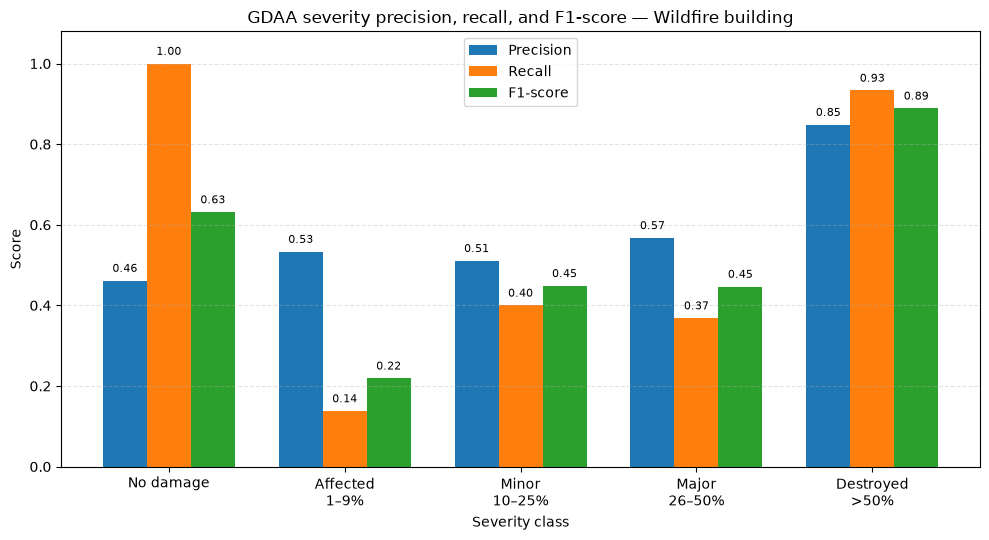

In [34]:
# Precision, recall, and F1-score for wildfire building severity evaluation

scenario = "wildfire_building"
scenario_label = "Wildfire building"

plot_df = (
    gdaa_severity_metrics_plot[
        gdaa_severity_metrics_plot["scenario"] == scenario
    ]
    .sort_values("label_id")
    .copy()
)

# Shorter labels for cleaner plotting
wildfire_label_map = {
    "0_No_Damage": "No damage",
    "1_Affected_1_9": "Affected\n1–9%",
    "2_Minor_10_25": "Minor\n10–25%",
    "3_Major_26_50": "Major\n26–50%",
    "4_Destroyed_50plus": "Destroyed\n>50%",
}

plot_df["display_label"] = (
    plot_df["label"]
    .map(wildfire_label_map)
    .fillna(plot_df["label"])
)

metrics = ["precision", "recall", "f1"]
metric_labels = ["Precision", "Recall", "F1-score"]

x = np.arange(len(plot_df))
width = 0.25

plt.figure(figsize=(10, 5.5))

for i, metric in enumerate(metrics):
    bars = plt.bar(
        x + i * width,
        plot_df[metric],
        width,
        label=metric_labels[i],
    )

    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.015,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=8,
        )

plt.xticks(
    x + width,
    plot_df["display_label"],
)

plt.ylim(0, 1.08)
plt.ylabel("Score")
plt.xlabel("Severity class")
plt.title(f"GDAA severity precision, recall, and F1-score — {scenario_label}")
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(frameon=True)

save_fig("gdaa_severity_precision_recall_f1_wildfire_building.png")

The wildfire-building scenario shows strong performance for extreme classes, especially destroyed buildings, but weaker performance for intermediate damage levels.

In [35]:
def build_severity_confusion_matrix(confusion_df, metrics_df, scenario):
    """
    Build a scenario-specific severity confusion matrix.

    The raw file stores rows as ground-truth labels and prediction columns as pred_0, pred_1, ...
    This function converts that format into a square matrix with readable severity labels.
    """
    scenario_conf = confusion_df[
        confusion_df["scenario"] == scenario
    ].copy()
    
    scenario_metrics = metrics_df[
        metrics_df["scenario"] == scenario
    ].copy()
    
    scenario_metrics = scenario_metrics.sort_values("label_id")
    
    id_to_label = dict(
        zip(
            scenario_metrics["label_id"].astype(int),
            scenario_metrics["label"].astype(str)
        )
    )
    
    pred_cols = []
    pred_labels = []
    
    for label_id in sorted(id_to_label.keys()):
        col = f"pred_{label_id}"
        if col in scenario_conf.columns:
            pred_cols.append(col)
            pred_labels.append(id_to_label[label_id])
    
    matrix = scenario_conf[["gt_label"] + pred_cols].copy()
    matrix = matrix.set_index("gt_label")
    matrix.columns = pred_labels
    matrix = matrix.fillna(0).astype(int)
    
    return matrix


gdaa_severity_cm_cross_view = build_severity_confusion_matrix(
    gdaa_severity_confusion,
    gdaa_severity_metrics,
    "cross_view_svi_rsi"
)

gdaa_severity_cm_cross_view

,Mild,Moderate,Severe
gt_label,,,
Mild,3,40,7
Moderate,0,19,31
Severe,0,31,19


Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gdaa_severity_confusion_matrix_cross_view_svi_rsi.png


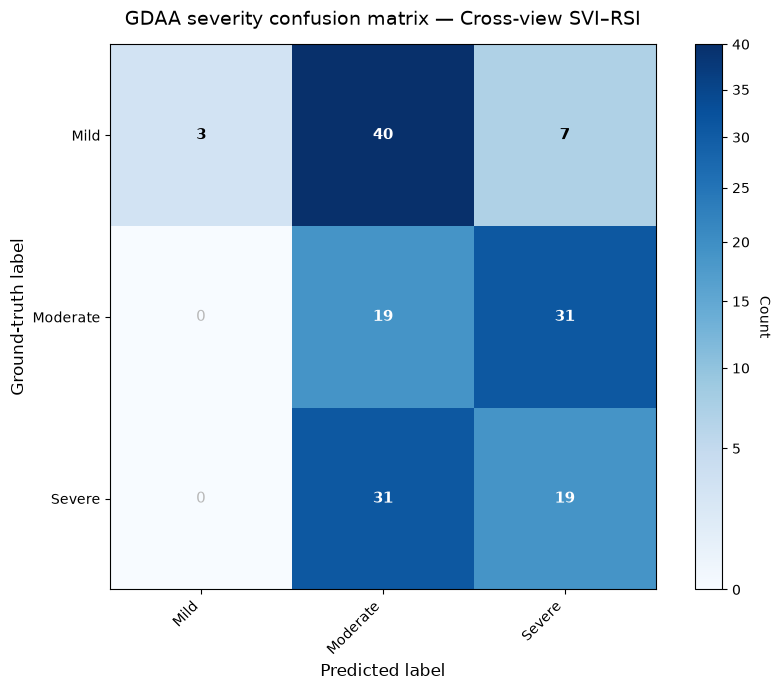

In [36]:
plot_confusion_matrix(
    gdaa_severity_cm_cross_view,
    title="GDAA severity confusion matrix — Cross-view SVI–RSI",
    filename="gdaa_severity_confusion_matrix_cross_view_svi_rsi.png",
    show_zeros=True,
)

### Cross-view SVI–RSI severity confusion matrix

The confusion matrix shows that the GDAA component has limited discriminative ability for severity estimation in the cross-view SVI–RSI scenario. Most Mild cases are overestimated as Moderate, while a substantial confusion is also observed between Moderate and Severe classes. This behavior suggests that the model tends to favor middle-to-high severity predictions and struggles to preserve the lower end of the severity scale.

In [38]:
gdaa_severity_cm_pre_post = build_severity_confusion_matrix(
    gdaa_severity_confusion,
    gdaa_severity_metrics,
    "pre_post_svi"
)

gdaa_severity_cm_pre_post

,Mild,Moderate,Severe
gt_label,,,
Mild,5,31,14
Moderate,2,28,20
Severe,0,15,35


Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gdaa_severity_confusion_matrix_pre_post_svi.png


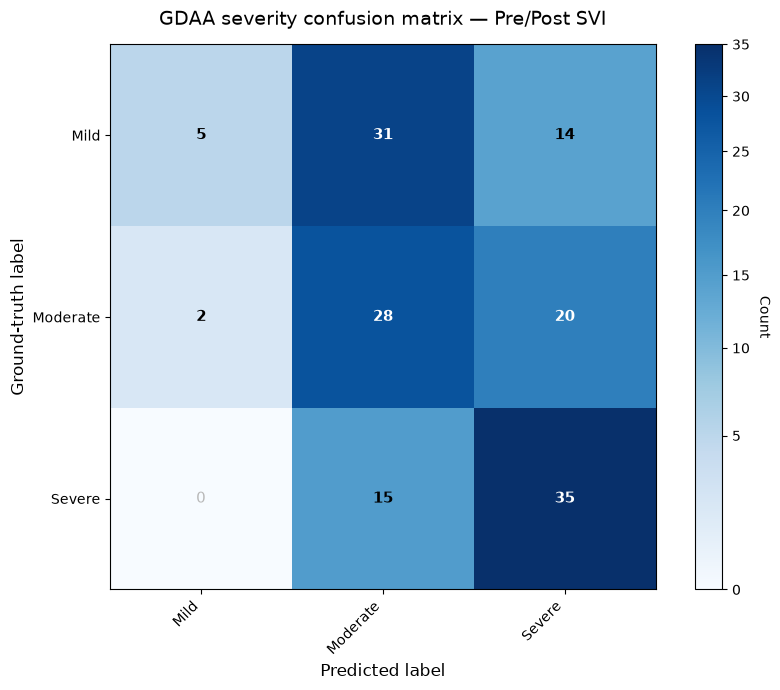

In [39]:
plot_confusion_matrix(
    gdaa_severity_cm_pre_post,
    title="GDAA severity confusion matrix — Pre/Post SVI",
    filename="gdaa_severity_confusion_matrix_pre_post_svi.png",
    show_zeros=True,
)

In [40]:
gdaa_severity_cm_wildfire = build_severity_confusion_matrix(
    gdaa_severity_confusion,
    gdaa_severity_metrics,
    "wildfire_building"
)

gdaa_severity_cm_wildfire

,0_No_Damage,1_Affected_1_9,2_Minor_10_25,3_Major_26_50,4_Destroyed_50plus
gt_label,,,,,
0_No_Damage,60,0,0,0,0
1_Affected_1_9,28,8,16,4,2
2_Minor_10_25,19,4,24,11,2
3_Major_26_50,21,2,7,21,6
4_Destroyed_50plus,2,1,0,1,56


### GDAA severity confusion matrix — Wildfire building

The following confusion matrix visualizes the severity classification performance of GDAA for the wildfire-building scenario. Rows correspond to ground-truth classes and columns correspond to predicted classes. Correct predictions appear on the main diagonal, while off-diagonal values indicate confusion between severity levels.

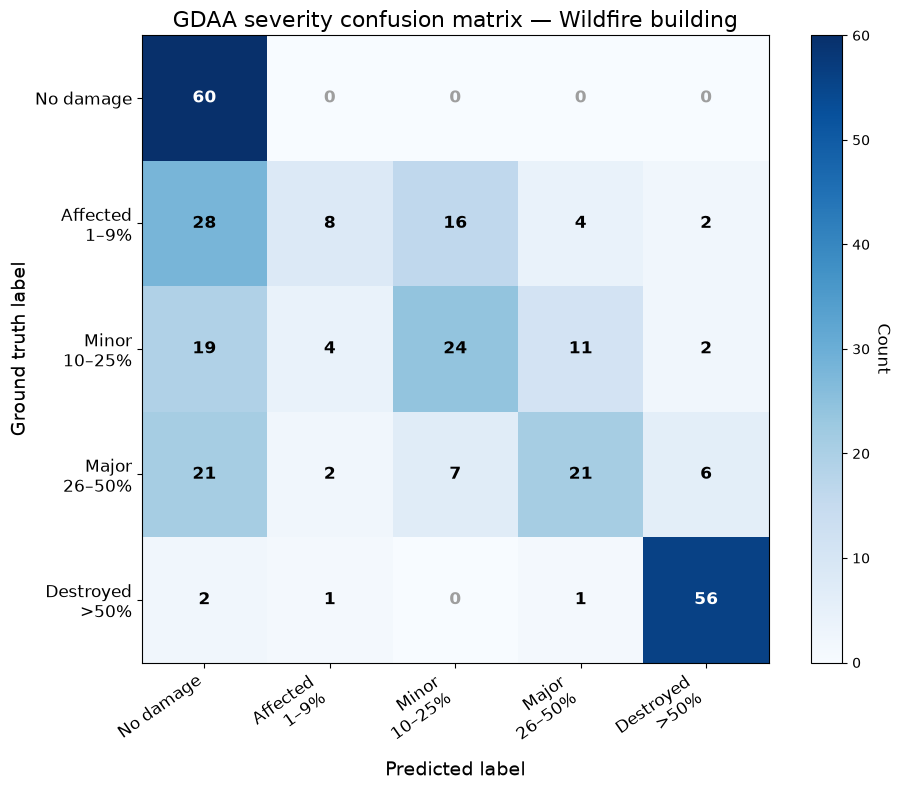

Saved to: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gdaa_severity_confusion_matrix_wildfire_building.png


In [42]:
cm = gdaa_severity_cm_wildfire.copy()

pretty_labels = [
    "No damage",
    "Affected\n1–9%",
    "Minor\n10–25%",
    "Major\n26–50%",
    "Destroyed\n>50%"
]

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(cm.values, cmap="Blues", vmin=0, vmax=cm.values.max())

ax.set_title("GDAA severity confusion matrix — Wildfire building", fontsize=16)
ax.set_xlabel("Predicted label", fontsize=14)
ax.set_ylabel("Ground truth label", fontsize=14)

ax.set_xticks(np.arange(len(pretty_labels)))
ax.set_yticks(np.arange(len(pretty_labels)))
ax.set_xticklabels(pretty_labels, rotation=35, ha="right", fontsize=12)
ax.set_yticklabels(pretty_labels, fontsize=12)

threshold = cm.values.max() / 2.0

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        value = int(cm.iloc[i, j])
        
        if value == 0:
            text_color = "#9e9e9e"
        else:
            text_color = "white" if value > threshold else "black"
        
        ax.text(
            j,
            i,
            f"{value}",
            ha="center",
            va="center",
            color=text_color,
            fontsize=12,
            fontweight="bold"
        )

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Count", rotation=270, labelpad=15, fontsize=12)

plt.tight_layout()

output_path = FIG_DIR / "gdaa_severity_confusion_matrix_wildfire_building.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved to: {output_path}")

The confusion matrix for the wildfire-building severity scenario shows that HERMES performs strongly at the two extremes of the severity scale. In particular, the *No damage* class is recognized perfectly, while the *Destroyed >50%* class also achieves very high recognition performance. In contrast, the intermediate severity classes (*Affected 1–9%*, *Minor 10–25%*, and *Major 26–50%*) are more frequently confused with one another, and especially with *No damage*. This indicates that the system is more reliable in distinguishing clearly unaffected and clearly destroyed buildings than in assigning fine-grained intermediate wildfire damage levels.

In [43]:
# Final summary table for GDAA severity evaluation

overall_total = gdaa_severity_by_scenario["total"].sum()
overall_correct = gdaa_severity_by_scenario["correct"].sum()
overall_accuracy = overall_correct / overall_total

overall_mean_ncse = np.average(
    gdaa_severity_by_scenario["mean_ncse"],
    weights=gdaa_severity_by_scenario["total"]
)

gdaa_severity_final_summary = pd.DataFrame([
    {
        "metric": "Overall exact severity accuracy",
        "value": overall_accuracy,
    },
    {
        "metric": "Overall correct cases",
        "value": int(overall_correct),
    },
    {
        "metric": "Overall evaluated cases",
        "value": int(overall_total),
    },
    {
        "metric": "Weighted mean NCSE",
        "value": overall_mean_ncse,
    },
    {
        "metric": "Best scenario by accuracy",
        "value": "wildfire_building",
    },
    {
        "metric": "Most difficult scenario by accuracy",
        "value": "cross_view_svi_rsi",
    },
])

gdaa_severity_final_summary

,metric,value
0,Overall exact severity accuracy,0.467227
1,Overall correct cases,278
2,Overall evaluated cases,595
3,Weighted mean NCSE,0.265126
4,Best scenario by accuracy,wildfire_building
5,Most difficult scenario by accuracy,cross_view_svi_rsi


### 5.10 Overall Interpretation of GDAA Severity Evaluation

The GeoDamageAnalysis Agent achieved an overall exact severity accuracy of 0.4672 across 595 evaluated cases. This confirms that severity estimation is substantially more difficult than hazard classification and input-mode recognition.

Performance varied considerably across scenarios. The wildfire-building scenario achieved the strongest results, with an exact accuracy of 0.5729 and the lowest mean NCSE of 0.1754. This indicates that the model is more reliable when estimating building-level wildfire damage, particularly when the damage state is visually clear. The pre/post SVI scenario achieved moderate performance, with an exact accuracy of 0.4533 and a mean NCSE of 0.3200. The cross-view SVI–RSI scenario was the most challenging, with an exact accuracy of 0.2733 and the highest mean NCSE of 0.3867.

The per-class results and confusion matrices show that the agent struggles with mild and intermediate severity levels. In both the cross-view SVI–RSI and pre/post SVI scenarios, mild cases are frequently overestimated as moderate or severe. In the wildfire-building scenario, the system performs well for the two extremes of the severity scale, especially `No damage` and `Destroyed >50%`, but has weaker performance for intermediate damage classes such as `Affected 1–9%`, `Minor 10–25%`, and `Major 26–50%`.

Overall, the severity evaluation identifies ordinal damage estimation as a key bottleneck in HERMES. The results suggest that the system can recognize clear low-damage and high-damage cases more reliably than fine-grained intermediate severity levels. This limitation should be considered when interpreting downstream reasoning reports, especially in cases where operational decisions depend on precise severity ranking.

### 5.11 Figure Captions for Thesis

**Figure X. GDAA severity exact accuracy by scenario.**  
Exact severity-classification accuracy for the GeoDamageAnalysis Agent across the evaluated scenarios. The wildfire-building scenario achieved the highest accuracy, while cross-view SVI–RSI was the most challenging scenario.

**Figure X. GDAA mean NCSE by scenario.**  
Mean Normalized Cross-Severity Error by scenario. Lower NCSE values indicate that incorrect predictions are closer to the correct ordinal severity class. The wildfire-building scenario achieved the lowest mean NCSE.

**Figure X. GDAA severity accuracy and NCSE by scenario.**  
Comparison of exact accuracy and mean NCSE across severity-evaluation scenarios. The results show that wildfire-building severity estimation performs best, while cross-view SVI–RSI has both the lowest exact accuracy and the highest ordinal error.

**Figure X. GDAA severity precision, recall, and F1-score — Cross-view SVI–RSI.**  
Per-class precision, recall, and F1-score for cross-view SVI–RSI severity classification. The model shows very low recall for mild damage, indicating that most mild cases are overestimated as higher severity classes.

**Figure X. GDAA severity precision, recall, and F1-score — Pre/Post SVI.**  
Per-class precision, recall, and F1-score for pre/post SVI severity classification. The model performs best for severe cases, while mild damage remains difficult due to very low recall.

**Figure X. GDAA severity precision, recall, and F1-score — Wildfire building.**  
Per-class precision, recall, and F1-score for wildfire-building severity classification. The model performs strongly for destroyed buildings, while intermediate wildfire damage classes remain more difficult to identify.

**Figure X. GDAA severity confusion matrix — Cross-view SVI–RSI.**  
Confusion matrix for severity classification in the cross-view SVI–RSI scenario. The matrix shows that most mild cases are overestimated as moderate, while moderate and severe cases are frequently confused.

**Figure X. GDAA severity confusion matrix — Pre/Post SVI.**  
Confusion matrix for severity classification in the pre/post SVI scenario. The matrix shows improved performance compared with cross-view SVI–RSI, especially for severe cases, but mild damage remains difficult to detect.

**Figure X. GDAA severity confusion matrix — Wildfire building.**  
Confusion matrix for wildfire-building severity classification. The model recognizes no-damage and destroyed cases effectively, but intermediate severity levels are frequently confused with adjacent or lower-severity categories.

## 6. Evaluation 4 — GeoDamageAnalysis Agent Object-Indicator Evaluation

This evaluation assesses the ability of the GeoDamageAnalysis Agent to identify damage-related object indicators.

Unlike severity estimation, object-indicator detection is treated as a multi-label task. A single case may contain multiple relevant indicators, such as debris, fallen trees, flooded areas, damaged buildings, or downed power lines.

The evaluation therefore uses multi-label metrics, including macro F1-score, micro F1-score, micro precision, micro recall, and micro accuracy. These metrics provide complementary views of performance across both frequent and rare object indicators.

In [44]:
gdaa_object_metrics = load_csv(
    "evaluation/hermes_gdaa_object_indicator_full_metrics.csv"
)

gdaa_object_metrics = clean_columns(gdaa_object_metrics)

print("GDAA object-indicator metrics shape:", gdaa_object_metrics.shape)
print("Columns:")
print(gdaa_object_metrics.columns.tolist())

gdaa_object_metrics

GDAA object-indicator metrics shape: (15, 11)
Columns:
['scenario', 'object_indicator', 'support', 'tp', 'fp', 'fn', 'tn', 'precision', 'recall', 'f1', 'binary_accuracy']


,scenario,object_indicator,support,tp,fp,fn,tn,precision,recall,f1,binary_accuracy
0,ALL,Obj_Debris,206,189,57,17,37,0.768293,0.917476,0.836283,0.753333
1,ALL,Obj_FallenTree,128,94,53,34,119,0.639456,0.734375,0.683636,0.710000
2,ALL,Obj_Flooded,19,17,39,2,242,0.303571,0.894737,0.453333,0.863333
3,ALL,Obj_DamagedBldg,105,96,110,9,85,0.466019,0.914286,0.617363,0.603333
4,ALL,Obj_DownedLines,3,1,23,2,274,0.041667,0.333333,0.074074,0.916667
5,cross_view_svi_rsi,Obj_Debris,95,92,36,3,19,0.718750,0.968421,0.825112,0.740000
6,cross_view_svi_rsi,Obj_FallenTree,77,74,42,3,31,0.637931,0.961039,0.766839,0.700000
7,cross_view_svi_rsi,Obj_Flooded,17,16,37,1,96,0.301887,0.941176,0.457143,0.746667
8,cross_view_svi_rsi,Obj_DamagedBldg,28,24,69,4,53,0.258065,0.857143,0.396694,0.513333
9,cross_view_svi_rsi,Obj_DownedLines,3,1,14,2,133,0.066667,0.333333,0.111111,0.893333


In [45]:
# Prepare overall object-indicator metrics

gdaa_object_overall = gdaa_object_metrics[
    gdaa_object_metrics["scenario"] == "ALL"
].copy()

gdaa_object_overall = coerce_numeric(
    gdaa_object_overall,
    ["support", "tp", "fp", "fn", "tn", "precision", "recall", "f1", "binary_accuracy"]
)

object_label_map = {
    "Obj_Debris": "Debris",
    "Obj_FallenTree": "Fallen tree",
    "Obj_Flooded": "Flooded",
    "Obj_DamagedBldg": "Damaged building",
    "Obj_DownedLines": "Downed lines",
}

gdaa_object_overall["display_label"] = (
    gdaa_object_overall["object_indicator"]
    .map(object_label_map)
    .fillna(gdaa_object_overall["object_indicator"])
)

gdaa_object_overall = gdaa_object_overall.sort_values("f1", ascending=False)

gdaa_object_overall

,scenario,object_indicator,support,tp,fp,fn,tn,precision,recall,f1,binary_accuracy,display_label
0,ALL,Obj_Debris,206,189,57,17,37,0.768293,0.917476,0.836283,0.753333,Debris
1,ALL,Obj_FallenTree,128,94,53,34,119,0.639456,0.734375,0.683636,0.710000,Fallen tree
3,ALL,Obj_DamagedBldg,105,96,110,9,85,0.466019,0.914286,0.617363,0.603333,Damaged building
2,ALL,Obj_Flooded,19,17,39,2,242,0.303571,0.894737,0.453333,0.863333,Flooded
4,ALL,Obj_DownedLines,3,1,23,2,274,0.041667,0.333333,0.074074,0.916667,Downed lines


Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gdaa_object_indicator_precision_recall_f1_overall.png


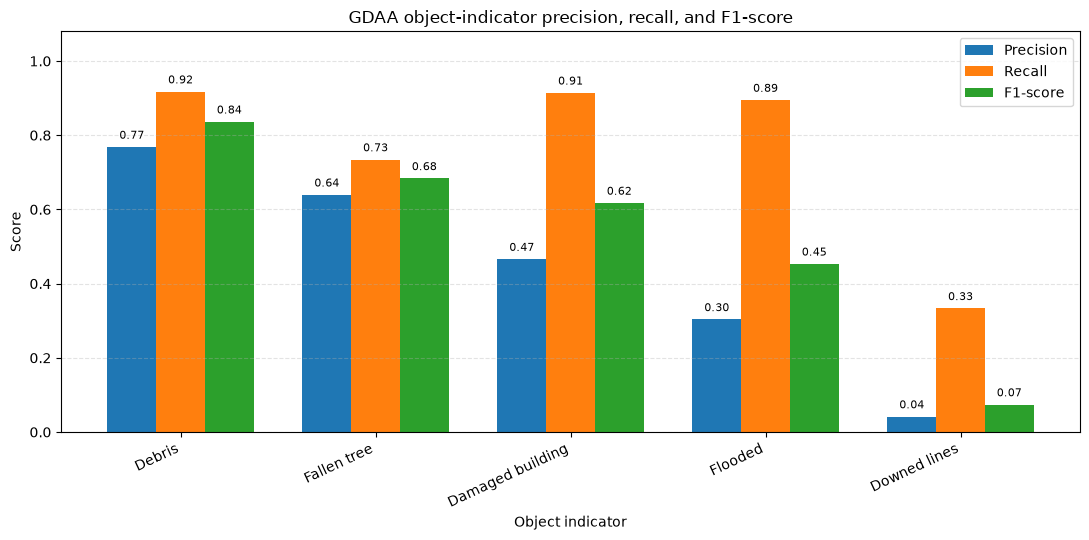

In [46]:
# Overall precision, recall, and F1-score by object indicator

plot_df = gdaa_object_overall.copy()

metrics = ["precision", "recall", "f1"]
metric_labels = ["Precision", "Recall", "F1-score"]

x = np.arange(len(plot_df))
width = 0.25

plt.figure(figsize=(11, 5.5))

for i, metric in enumerate(metrics):
    bars = plt.bar(
        x + i * width,
        plot_df[metric],
        width,
        label=metric_labels[i],
    )

    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.015,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=8,
        )

plt.xticks(
    x + width,
    plot_df["display_label"],
    rotation=25,
    ha="right",
)

plt.ylim(0, 1.08)
plt.ylabel("Score")
plt.xlabel("Object indicator")
plt.title("GDAA object-indicator precision, recall, and F1-score")
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(frameon=True)

save_fig("gdaa_object_indicator_precision_recall_f1_overall.png")

Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gdaa_object_indicator_support_by_class.png


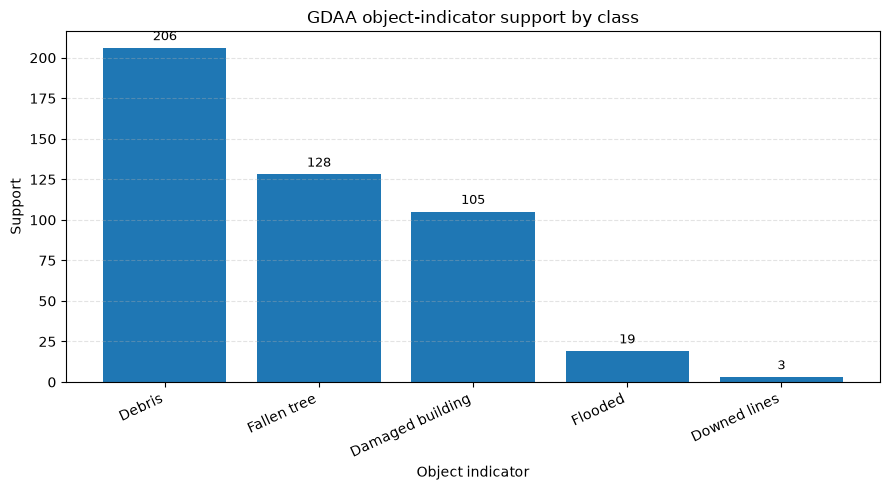

In [47]:
# Overall support by object indicator

plot_df = gdaa_object_overall.copy()
plot_df = plot_df.sort_values("support", ascending=False)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    plot_df["display_label"],
    plot_df["support"],
)

plt.ylabel("Support")
plt.xlabel("Object indicator")
plt.title("GDAA object-indicator support by class")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.35)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 3,
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

save_fig("gdaa_object_indicator_support_by_class.png")

In [48]:
gdaa_object_by_scenario = load_csv(
    "evaluation/hermes_gdaa_object_indicator_full_by_scenario.csv"
)

gdaa_object_by_scenario = clean_columns(gdaa_object_by_scenario)

print("GDAA object-indicator by-scenario shape:", gdaa_object_by_scenario.shape)
print("Columns:")
print(gdaa_object_by_scenario.columns.tolist())

gdaa_object_by_scenario

GDAA object-indicator by-scenario shape: (3, 13)
Columns:
['scenario', 'cases', 'macro_precision', 'macro_recall', 'macro_f1', 'micro_precision', 'micro_recall', 'micro_f1', 'micro_accuracy', 'tp', 'fp', 'fn', 'tn']


,scenario,cases,macro_precision,macro_recall,macro_f1,micro_precision,micro_recall,micro_f1,micro_accuracy,tp,fp,fn,tn
0,ALL,300,0.443801,0.758841,0.532938,0.584683,0.861171,0.696491,0.769333,397,282,64,757
1,cross_view_svi_rsi,150,0.396660,0.812223,0.511380,0.511111,0.940909,0.662400,0.718667,207,198,13,332
2,pre_post_svi,150,0.487539,0.540219,0.498572,0.693431,0.788382,0.737864,0.820000,190,84,51,425


Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gdaa_object_indicator_performance_by_scenario.png


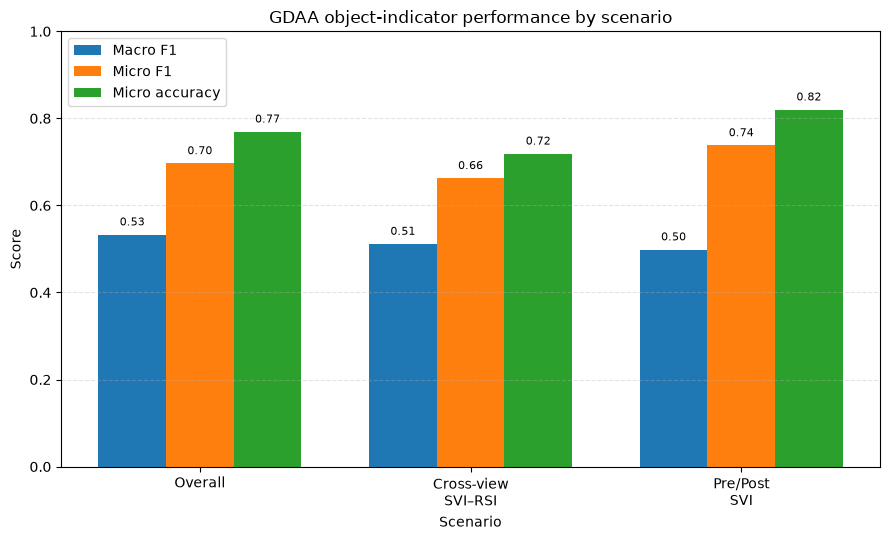

In [49]:
# Scenario-level object-indicator performance

gdaa_object_by_scenario_plot = gdaa_object_by_scenario.copy()

scenario_label_map = {
    "ALL": "Overall",
    "cross_view_svi_rsi": "Cross-view\nSVI–RSI",
    "pre_post_svi": "Pre/Post\nSVI",
}

gdaa_object_by_scenario_plot["scenario_label"] = (
    gdaa_object_by_scenario_plot["scenario"]
    .map(scenario_label_map)
    .fillna(gdaa_object_by_scenario_plot["scenario"])
)

gdaa_object_by_scenario_plot = coerce_numeric(
    gdaa_object_by_scenario_plot,
    [
        "cases",
        "macro_precision",
        "macro_recall",
        "macro_f1",
        "micro_precision",
        "micro_recall",
        "micro_f1",
        "micro_accuracy",
        "tp",
        "fp",
        "fn",
        "tn",
    ]
)

metrics = ["macro_f1", "micro_f1", "micro_accuracy"]
metric_labels = ["Macro F1", "Micro F1", "Micro accuracy"]

x = np.arange(len(gdaa_object_by_scenario_plot))
width = 0.25

plt.figure(figsize=(9, 5.5))

for i, metric in enumerate(metrics):
    bars = plt.bar(
        x + i * width,
        gdaa_object_by_scenario_plot[metric],
        width,
        label=metric_labels[i],
    )
    
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.015,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=8,
        )

plt.xticks(
    x + width,
    gdaa_object_by_scenario_plot["scenario_label"],
)

plt.ylim(0, 1.0)
plt.ylabel("Score")
plt.xlabel("Scenario")
plt.title("GDAA object-indicator performance by scenario")
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(frameon=True)

save_fig("gdaa_object_indicator_performance_by_scenario.png")

Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gdaa_object_indicator_micro_metrics_by_scenario.png


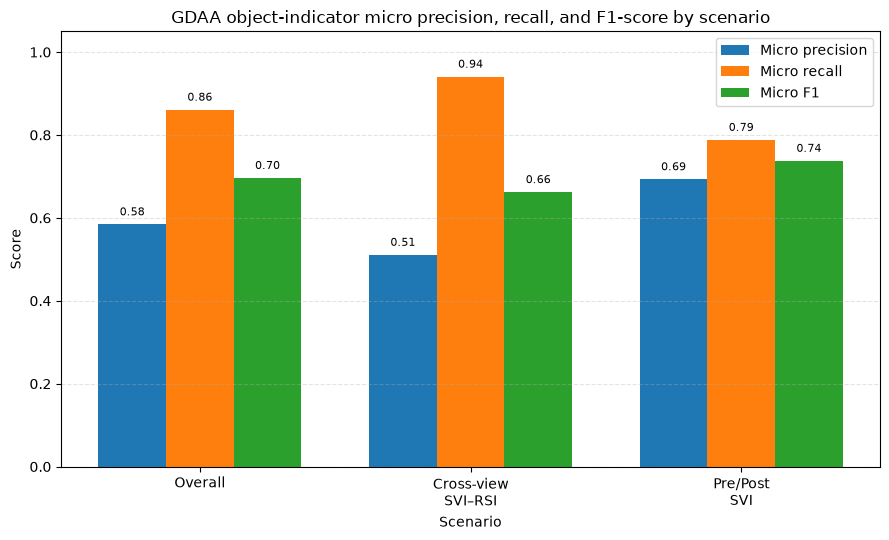

In [50]:
# Scenario-level micro precision, recall, and F1-score

plot_df = gdaa_object_by_scenario_plot.copy()

metrics = ["micro_precision", "micro_recall", "micro_f1"]
metric_labels = ["Micro precision", "Micro recall", "Micro F1"]

x = np.arange(len(plot_df))
width = 0.25

plt.figure(figsize=(9, 5.5))

for i, metric in enumerate(metrics):
    bars = plt.bar(
        x + i * width,
        plot_df[metric],
        width,
        label=metric_labels[i],
    )
    
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.015,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=8,
        )

plt.xticks(
    x + width,
    plot_df["scenario_label"],
)

plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.xlabel("Scenario")
plt.title("GDAA object-indicator micro precision, recall, and F1-score by scenario")
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(frameon=True)

save_fig("gdaa_object_indicator_micro_metrics_by_scenario.png")

In [51]:
# Per-scenario F1-score by object indicator

gdaa_object_per_scenario = gdaa_object_metrics[
    gdaa_object_metrics["scenario"] != "ALL"
].copy()

gdaa_object_per_scenario = coerce_numeric(
    gdaa_object_per_scenario,
    ["support", "tp", "fp", "fn", "tn", "precision", "recall", "f1", "binary_accuracy"]
)

object_label_map = {
    "Obj_Debris": "Debris",
    "Obj_FallenTree": "Fallen tree",
    "Obj_Flooded": "Flooded",
    "Obj_DamagedBldg": "Damaged building",
    "Obj_DownedLines": "Downed lines",
}

scenario_label_map = {
    "cross_view_svi_rsi": "Cross-view\nSVI–RSI",
    "pre_post_svi": "Pre/Post\nSVI",
}

gdaa_object_per_scenario["display_label"] = (
    gdaa_object_per_scenario["object_indicator"]
    .map(object_label_map)
    .fillna(gdaa_object_per_scenario["object_indicator"])
)

gdaa_object_per_scenario["scenario_label"] = (
    gdaa_object_per_scenario["scenario"]
    .map(scenario_label_map)
    .fillna(gdaa_object_per_scenario["scenario"])
)

pivot_f1 = gdaa_object_per_scenario.pivot(
    index="display_label",
    columns="scenario_label",
    values="f1"
)

# Keep a readable object-indicator order
indicator_order = [
    "Debris",
    "Fallen tree",
    "Damaged building",
    "Flooded",
    "Downed lines",
]

pivot_f1 = pivot_f1.loc[indicator_order]

pivot_f1

scenario_label,Cross-view\nSVI–RSI,Pre/Post\nSVI
display_label,,
Debris,0.825112,0.847162
Fallen tree,0.766839,0.487805
Damaged building,0.396694,0.757895
Flooded,0.457143,0.400000
Downed lines,0.111111,0.000000


Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gdaa_object_indicator_f1_by_scenario.png


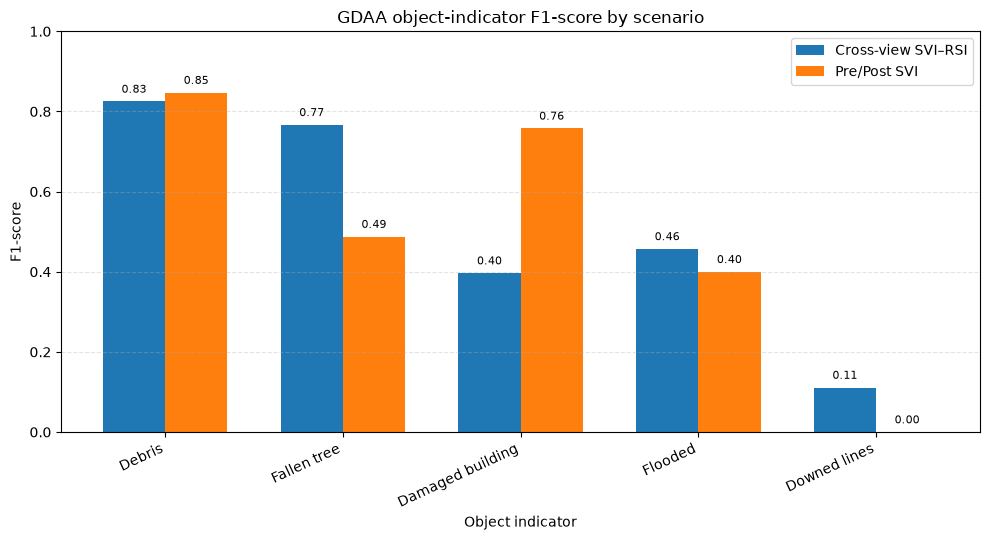

In [52]:
# F1-score by object indicator and scenario

plot_df = pivot_f1.copy()

x = np.arange(len(plot_df.index))
width = 0.35

plt.figure(figsize=(10, 5.5))

bars_cross = plt.bar(
    x - width / 2,
    plot_df["Cross-view\nSVI–RSI"],
    width,
    label="Cross-view SVI–RSI",
)

bars_prepost = plt.bar(
    x + width / 2,
    plot_df["Pre/Post\nSVI"],
    width,
    label="Pre/Post SVI",
)

plt.xticks(
    x,
    plot_df.index,
    rotation=25,
    ha="right",
)

plt.ylim(0, 1.0)
plt.ylabel("F1-score")
plt.xlabel("Object indicator")
plt.title("GDAA object-indicator F1-score by scenario")
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(frameon=True)

for bars in [bars_cross, bars_prepost]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.015,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=8,
        )

save_fig("gdaa_object_indicator_f1_by_scenario.png")

### 6.5 Overall Interpretation of GDAA Object-Indicator Evaluation

The GeoDamageAnalysis Agent achieved moderate-to-strong performance in the multi-label object-indicator detection task. Overall, the model reached a macro F1-score of 0.5329, a micro F1-score of 0.6965, and a micro accuracy of 0.7693 across 300 evaluated cases.

The results show that the model is generally recall-oriented. Overall micro recall reached 0.8612, while micro precision was lower at 0.5847. This indicates that the model identifies many of the true object indicators, but also produces a substantial number of false positives.

At the object-indicator level, Debris was the strongest class, with an F1-score of 0.8363. Fallen tree and damaged building also achieved useful performance, although damaged building showed high recall but lower precision, indicating over-prediction. Flooded areas achieved high recall but low precision, while downed lines achieved very low F1-score. However, the downed-lines result should be interpreted cautiously because the class has extremely limited support.

Scenario-level results show that Pre/Post SVI achieved the strongest micro-level performance, with a micro F1-score of 0.7379 and micro accuracy of 0.8200. Cross-view SVI–RSI achieved very high micro recall but lower micro precision, suggesting that the agent tends to over-predict object indicators in the cross-view setting.

Overall, the object-indicator evaluation shows that HERMES can extract useful damage-related signals from imagery, especially for frequent and visually salient indicators. However, class imbalance and false-positive behavior remain important limitations, particularly for rare or visually ambiguous indicators.

In [53]:
# Final summary table for GDAA object-indicator evaluation

gdaa_object_overall_row = gdaa_object_by_scenario[
    gdaa_object_by_scenario["scenario"] == "ALL"
].iloc[0]

gdaa_object_final_summary = pd.DataFrame([
    {
        "metric": "Evaluated cases",
        "value": int(gdaa_object_overall_row["cases"]),
    },
    {
        "metric": "Macro precision",
        "value": gdaa_object_overall_row["macro_precision"],
    },
    {
        "metric": "Macro recall",
        "value": gdaa_object_overall_row["macro_recall"],
    },
    {
        "metric": "Macro F1",
        "value": gdaa_object_overall_row["macro_f1"],
    },
    {
        "metric": "Micro precision",
        "value": gdaa_object_overall_row["micro_precision"],
    },
    {
        "metric": "Micro recall",
        "value": gdaa_object_overall_row["micro_recall"],
    },
    {
        "metric": "Micro F1",
        "value": gdaa_object_overall_row["micro_f1"],
    },
    {
        "metric": "Micro accuracy",
        "value": gdaa_object_overall_row["micro_accuracy"],
    },
    {
        "metric": "Best object indicator by F1",
        "value": gdaa_object_overall.sort_values("f1", ascending=False).iloc[0]["display_label"],
    },
    {
        "metric": "Weakest object indicator by F1",
        "value": gdaa_object_overall.sort_values("f1", ascending=True).iloc[0]["display_label"],
    },
])

gdaa_object_final_summary

,metric,value
0,Evaluated cases,300
1,Macro precision,0.443801
2,Macro recall,0.758841
3,Macro F1,0.532938
4,Micro precision,0.584683
5,Micro recall,0.861171
6,Micro F1,0.696491
7,Micro accuracy,0.769333
8,Best object indicator by F1,Debris
9,Weakest object indicator by F1,Downed lines


### 6.6 Overall Interpretation of GDAA Object-Indicator Evaluation

The GeoDamageAnalysis Agent achieved moderate-to-strong performance in the multi-label object-indicator detection task. Across 300 evaluated cases, the model reached a macro F1-score of 0.5329, a micro F1-score of 0.6965, and a micro accuracy of 0.7693.

The results indicate that the model is recall-oriented. Overall micro recall reached 0.8612, while micro precision was lower at 0.5847. This means that the agent successfully identifies many true object indicators, but also produces a substantial number of false positives.

At the object-indicator level, Debris was the strongest class, achieving an F1-score of 0.8363. Fallen tree and damaged building also showed useful performance, although damaged building had high recall and lower precision, suggesting over-prediction. Flooded areas showed high recall but low precision. Downed lines achieved the weakest F1-score, but this result should be interpreted cautiously because the class had only three positive samples.

Scenario-level results show that Pre/Post SVI achieved the strongest micro-level performance, with a micro F1-score of 0.7379 and micro accuracy of 0.8200. Cross-view SVI–RSI achieved very high micro recall but lower micro precision, indicating a tendency to over-predict object indicators in the cross-view setting.

Overall, the object-indicator evaluation shows that HERMES can extract useful damage-related signals from imagery, especially for frequent and visually salient indicators. However, class imbalance and false-positive behavior remain important limitations, particularly for rare or visually ambiguous indicators.

## 7. Evaluation 5 — GeoReasoning Agent Internal Consistency Evaluation

This evaluation assesses the internal consistency and faithfulness of the reports generated by the GeoReasoning Agent.

Unlike the previous evaluations, this task does not evaluate image-level classification directly. Instead, it evaluates whether the generated disaster-response reports are coherent, factually consistent with the structured intermediate outputs, causally plausible, sufficiently complete, and practically feasible.

The evaluation uses a rubric-based scoring protocol with four criteria:

- Factual consistency
- Causal plausibility
- Completeness
- Action feasibility

Each criterion is scored on a 1–5 scale. The evaluation also assigns an overall verdict for each report.

In [54]:
gra_internal_scores = load_csv(
    "evaluation/gra_report_evaluation_set/rubric_evaluation/gra_report_rubric_scores.csv"
)

gra_internal_scores = clean_columns(gra_internal_scores)

print("GRA internal consistency scores shape:", gra_internal_scores.shape)
print("Columns:")
print(gra_internal_scores.columns.tolist())

gra_internal_scores.head(10)

GRA internal consistency scores shape: (41, 20)
Columns:
['run_timestamp', 'scenario', 'case_id', 'report_json_path', 'status', 'model', 'factual_consistency', 'causal_plausibility', 'completeness', 'action_feasibility', 'overall_mean', 'overall_verdict', 'major_issues', 'unsupported_claims', 'factual_consistency_rationale', 'causal_plausibility_rationale', 'completeness_rationale', 'action_feasibility_rationale', 'raw_eval_json', 'error_summary']


,run_timestamp,scenario,case_id,report_json_path,status,model,factual_consistency,causal_plausibility,completeness,action_feasibility,overall_mean,overall_verdict,major_issues,unsupported_claims,factual_consistency_rationale,causal_plausibility_rationale,completeness_rationale,action_feasibility_rationale,raw_eval_json,error_summary
0,2026-08-26T08:13:20,cross_view_svi_rsi,133774193036070_Satellite__133774193036070_SVI,evaluation\gra_report_evaluation_set\cross_view_svi_rsi\reports\133774193036070\cross_view_svi_rsi__133774193036070_Satellite__133774193036070_SVI_report.json,success,gemini-3.1-pro-preview,5.0,5.0,5.0,5.0,5.00,pass,[],[],"The final report accurately reflects all structured upstream evidence, including the input mode, hazard type, image restoration metrics, severity level, aff...","The report logically connects the observed damage (widespread defoliation, damaged palm fronds, and vegetation debris) to the identified hurricane hazard. T...","The report is comprehensive, covering all expected elements: the input scenario, detailed image restoration metadata, damage findings with cross-view eviden...","The recommended actions (prioritizing debris removal, conducting ground-level inspections for minor structural damage, verifying road accessibility, and mon...","{""factual_consistency"": {""score"": 5, ""rationale"": ""The final report accurately reflects all structured upstream evidence, including the input mode, hazard t...",NaN
1,2026-08-26T08:13:37,cross_view_svi_rsi,137433545842697_Satellite__137433545842697_SVI,evaluation\gra_report_evaluation_set\cross_view_svi_rsi\reports\137433545842697\cross_view_svi_rsi__137433545842697_Satellite__137433545842697_SVI_report.json,success,gemini-3.1-pro-preview,5.0,5.0,5.0,5.0,5.00,pass,[],[],"The final report accurately reflects all structured evidence, including the input mode, hazard type, image restoration details (including specific Q values ...","The report logically connects the hurricane hazard to the observed widespread vegetation defoliation and browning, correctly noting the absence of catastrop...","The report is comprehensive, covering all expected elements: scenario/input, detailed image restoration status, damage findings, severity, supporting eviden...","The recommended actions are operationally useful, safe, and realistic. They appropriately suggest using the cross-view imagery for prioritization and access...","{""factual_consistency"": {""score"": 5, ""rationale"": ""The final report accurately reflects all structured evidence, including the input mode, hazard type, imag...",NaN
2,2026-08-26T08:13:55,cross_view_svi_rsi,137583195510477_Satellite__137583195510477_SVI,evaluation\gra_report_evaluation_set\cross_view_svi_rsi\reports\137583195510477\cross_view_svi_rsi__137583195510477_Satellite__137583195510477_SVI_report.json,success,gemini-3.1-pro-preview,5.0,4.0,4.0,5.0,4.50,pass,[],[],"The final report is entirely consistent with the upstream structured evidence. It accurately reflects the severity (Moderate), confidence score (0.85), affe...","The report correctly frames the event as a hurricane damage-assessment scenario and lists damage consistent with such an event (e.g., defoliation, wind-stre...","The report successfully covers almost all key elements expected: scenario/input, image restoration status, damage findings, severity, supporting evidence, u...","The recommended actions are highly feasible, safe, and directly aligned with the evidence. Prioritizing ground-level verification of roof damage, assessing ...","{""factual_consistency"": {""score"": 5, ""rationale"": ""The final report is entirely consistent with the upstream structured evidence. It accurately reflects the...",NaN
3,2026-08-26T08:14:07,cross_view_svi_rsi,138474125927472_Satellite__138474125927472_SVI,evaluation\gra_report_evaluation_set\cross_view_svi_rsi\reports\138474125927472\cross_view_svi_rsi__138474125927472_Satellite__138474125927472_SVI_report.json,success,gemini-3.1-pro-pr

In [55]:
# Inspect status, scenarios, and verdict distribution before plotting

print("Status values:")
print(gra_internal_scores["status"].value_counts(dropna=False))
print()

print("Scenario values:")
print(gra_internal_scores["scenario"].value_counts(dropna=False))
print()

print("Verdict values:")
print(gra_internal_scores["overall_verdict"].value_counts(dropna=False))


Status values:
status
success    40
failed      1
Name: count, dtype: int64

Scenario values:
scenario
object_detection      11
cross_view_svi_rsi    10
pre_post_svi          10
wildfire_building     10
Name: count, dtype: int64

Verdict values:
overall_verdict
pass          32
borderline     6
fail           2
NaN            1
Name: count, dtype: int64


In [56]:
# Keep only successfully evaluated GRA reports

gra_internal_valid = gra_internal_scores[
    gra_internal_scores["status"] == "success"
].copy()

gra_internal_valid = coerce_numeric(
    gra_internal_valid,
    [
        "factual_consistency",
        "causal_plausibility",
        "completeness",
        "action_feasibility",
        "overall_mean",
    ]
)

print("Valid GRA internal reports:", len(gra_internal_valid))
print()

print("Scenario distribution:")
print(gra_internal_valid["scenario"].value_counts())
print()

print("Verdict distribution:")
print(gra_internal_valid["overall_verdict"].value_counts())

gra_internal_valid.head()

Valid GRA internal reports: 40

Scenario distribution:
scenario
cross_view_svi_rsi    10
pre_post_svi          10
wildfire_building     10
object_detection      10
Name: count, dtype: int64

Verdict distribution:
overall_verdict
pass          32
borderline     6
fail           2
Name: count, dtype: int64


,run_timestamp,scenario,case_id,report_json_path,status,model,factual_consistency,causal_plausibility,completeness,action_feasibility,overall_mean,overall_verdict,major_issues,unsupported_claims,factual_consistency_rationale,causal_plausibility_rationale,completeness_rationale,action_feasibility_rationale,raw_eval_json,error_summary
0,2026-08-26T08:13:20,cross_view_svi_rsi,133774193036070_Satellite__133774193036070_SVI,evaluation\gra_report_evaluation_set\cross_view_svi_rsi\reports\133774193036070\cross_view_svi_rsi__133774193036070_Satellite__133774193036070_SVI_report.json,success,gemini-3.1-pro-preview,5.0,5.0,5.0,5.0,5.0,pass,[],[],"The final report accurately reflects all structured upstream evidence, including the input mode, hazard type, image restoration metrics, severity level, aff...","The report logically connects the observed damage (widespread defoliation, damaged palm fronds, and vegetation debris) to the identified hurricane hazard. T...","The report is comprehensive, covering all expected elements: the input scenario, detailed image restoration metadata, damage findings with cross-view eviden...","The recommended actions (prioritizing debris removal, conducting ground-level inspections for minor structural damage, verifying road accessibility, and mon...","{""factual_consistency"": {""score"": 5, ""rationale"": ""The final report accurately reflects all structured upstream evidence, including the input mode, hazard t...",NaN
1,2026-08-26T08:13:37,cross_view_svi_rsi,137433545842697_Satellite__137433545842697_SVI,evaluation\gra_report_evaluation_set\cross_view_svi_rsi\reports\137433545842697\cross_view_svi_rsi__137433545842697_Satellite__137433545842697_SVI_report.json,success,gemini-3.1-pro-preview,5.0,5.0,5.0,5.0,5.0,pass,[],[],"The final report accurately reflects all structured evidence, including the input mode, hazard type, image restoration details (including specific Q values ...","The report logically connects the hurricane hazard to the observed widespread vegetation defoliation and browning, correctly noting the absence of catastrop...","The report is comprehensive, covering all expected elements: scenario/input, detailed image restoration status, damage findings, severity, supporting eviden...","The recommended actions are operationally useful, safe, and realistic. They appropriately suggest using the cross-view imagery for prioritization and access...","{""factual_consistency"": {""score"": 5, ""rationale"": ""The final report accurately reflects all structured evidence, including the input mode, hazard type, imag...",NaN
2,2026-08-26T08:13:55,cross_view_svi_rsi,137583195510477_Satellite__137583195510477_SVI,evaluation\gra_report_evaluation_set\cross_view_svi_rsi\reports\137583195510477\cross_view_svi_rsi__137583195510477_Satellite__137583195510477_SVI_report.json,success,gemini-3.1-pro-preview,5.0,4.0,4.0,5.0,4.5,pass,[],[],"The final report is entirely consistent with the upstream structured evidence. It accurately reflects the severity (Moderate), confidence score (0.85), affe...","The report correctly frames the event as a hurricane damage-assessment scenario and lists damage consistent with such an event (e.g., defoliation, wind-stre...","The report successfully covers almost all key elements expected: scenario/input, image restoration status, damage findings, severity, supporting evidence, u...","The recommended actions are highly feasible, safe, and directly aligned with the evidence. Prioritizing ground-level verification of roof damage, assessing ...","{""factual_consistency"": {""score"": 5, ""rationale"": ""The final report is entirely consistent with the upstream structured evidence. It accurately reflects the...",NaN
3,2026-08-26T08:14:07,cross_view_svi_rsi,138474125927472_Satellite__138474125927472_SVI,evaluation\gra_report_evaluation_set\cross_view_svi_rsi\reports\138474125927472\cross_view_svi_rsi__138474125927472_Satellite__138474125927472_SVI_report.json,success,gemini-3.1-pro-previ

In [57]:
# Overall rubric-score summary for GRA internal consistency evaluation

gra_internal_criteria = [
    "factual_consistency",
    "causal_plausibility",
    "completeness",
    "action_feasibility",
    "overall_mean",
]

gra_internal_overall_summary = pd.DataFrame([
    {
        "criterion": "Factual consistency",
        "mean_score": gra_internal_valid["factual_consistency"].mean(),
    },
    {
        "criterion": "Causal plausibility",
        "mean_score": gra_internal_valid["causal_plausibility"].mean(),
    },
    {
        "criterion": "Completeness",
        "mean_score": gra_internal_valid["completeness"].mean(),
    },
    {
        "criterion": "Action feasibility",
        "mean_score": gra_internal_valid["action_feasibility"].mean(),
    },
    {
        "criterion": "Overall mean",
        "mean_score": gra_internal_valid["overall_mean"].mean(),
    },
])

gra_internal_overall_summary

,criterion,mean_score
0,Factual consistency,4.50000
1,Causal plausibility,4.75000
2,Completeness,4.57500
3,Action feasibility,4.70000
4,Overall mean,4.63125


Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gra_internal_consistency_rubric_scores.png


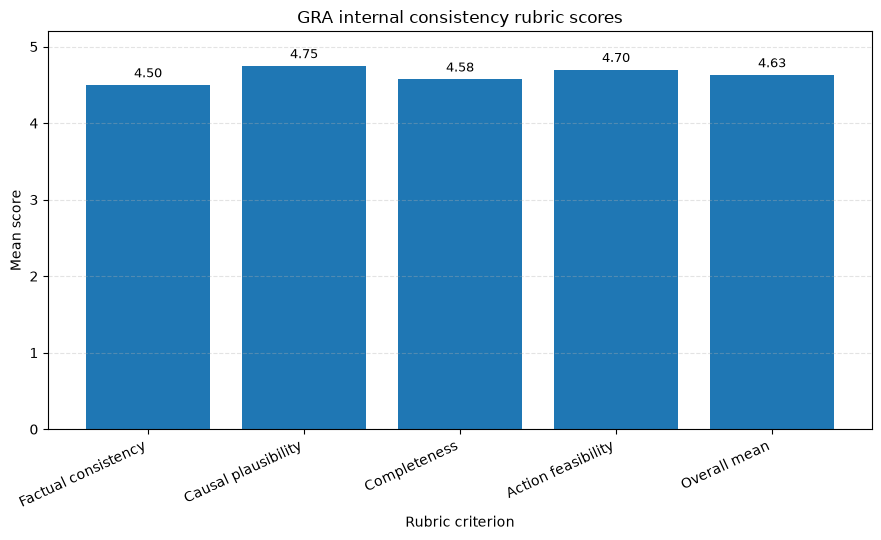

In [58]:
# Overall rubric scores for GRA internal consistency evaluation

plot_df = gra_internal_overall_summary.copy()

plt.figure(figsize=(9, 5.5))

bars = plt.bar(
    plot_df["criterion"],
    plot_df["mean_score"],
)

plt.ylim(0, 5.2)
plt.ylabel("Mean score")
plt.xlabel("Rubric criterion")
plt.title("GRA internal consistency rubric scores")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.35)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.06,
        f"{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

save_fig("gra_internal_consistency_rubric_scores.png")

Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gra_internal_consistency_verdict_distribution.png


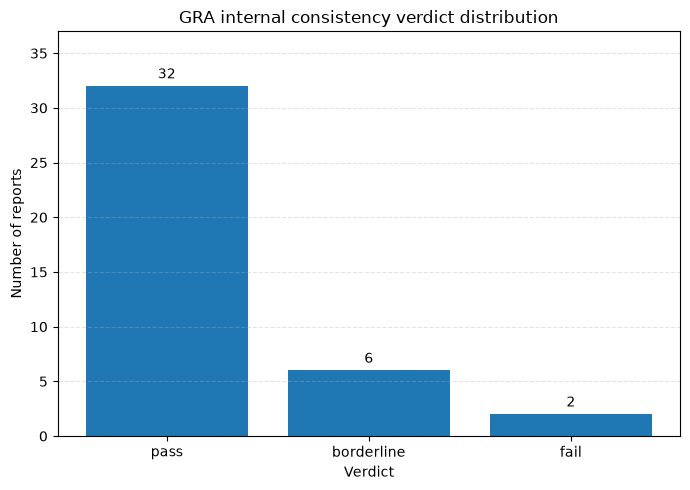

In [59]:
# Verdict distribution for GRA internal consistency evaluation

verdict_order = ["pass", "borderline", "fail"]

gra_internal_verdict_counts = (
    gra_internal_valid["overall_verdict"]
    .value_counts()
    .reindex(verdict_order)
    .fillna(0)
    .astype(int)
    .reset_index()
)

gra_internal_verdict_counts.columns = ["verdict", "count"]

plt.figure(figsize=(7, 5))

bars = plt.bar(
    gra_internal_verdict_counts["verdict"],
    gra_internal_verdict_counts["count"],
)

plt.ylabel("Number of reports")
plt.xlabel("Verdict")
plt.title("GRA internal consistency verdict distribution")
plt.ylim(0, gra_internal_verdict_counts["count"].max() + 5)
plt.grid(axis="y", linestyle="--", alpha=0.35)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.4,
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontsize=10,
    )

save_fig("gra_internal_consistency_verdict_distribution.png")

In [60]:
# Mean internal-consistency rubric scores by scenario

gra_internal_by_scenario = (
    gra_internal_valid
    .groupby("scenario")[
        [
            "factual_consistency",
            "causal_plausibility",
            "completeness",
            "action_feasibility",
            "overall_mean",
        ]
    ]
    .mean()
    .reset_index()
)

scenario_label_map = {
    "cross_view_svi_rsi": "Cross-view\nSVI–RSI",
    "pre_post_svi": "Pre/Post\nSVI",
    "wildfire_building": "Wildfire\nbuilding",
    "object_detection": "Object\ndetection",
}

gra_internal_by_scenario["scenario_label"] = (
    gra_internal_by_scenario["scenario"]
    .map(scenario_label_map)
    .fillna(gra_internal_by_scenario["scenario"])
)

gra_internal_by_scenario

,scenario,factual_consistency,causal_plausibility,completeness,action_feasibility,overall_mean,scenario_label
0,cross_view_svi_rsi,4.9,4.9,4.9,5.0,4.925,Cross-view\nSVI–RSI
1,object_detection,4.6,4.7,3.8,5.0,4.525,Object\ndetection
2,pre_post_svi,4.2,4.6,4.6,4.8,4.550,Pre/Post\nSVI
3,wildfire_building,4.3,4.8,5.0,4.0,4.525,Wildfire\nbuilding


Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gra_internal_consistency_overall_score_by_scenario.png


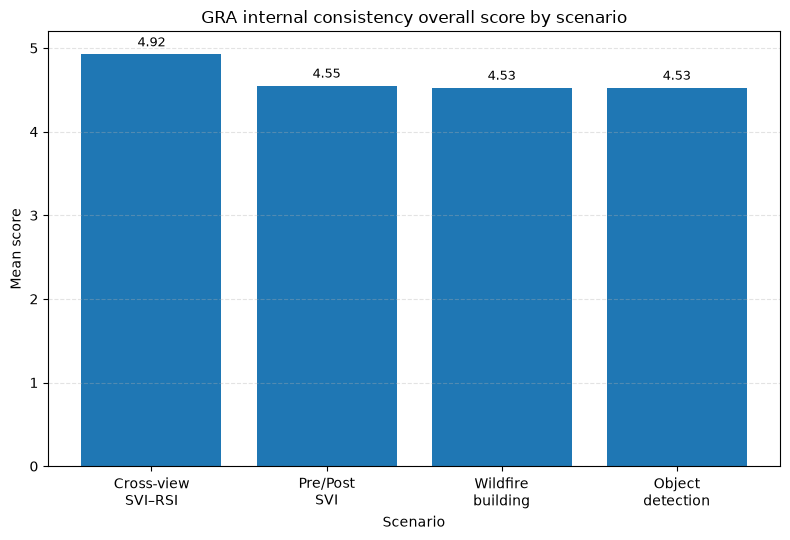

In [61]:
# Overall internal-consistency score by scenario

scenario_order = [
    "cross_view_svi_rsi",
    "pre_post_svi",
    "wildfire_building",
    "object_detection",
]

plot_df = (
    gra_internal_by_scenario
    .set_index("scenario")
    .loc[scenario_order]
    .reset_index()
)

plt.figure(figsize=(8, 5.5))

bars = plt.bar(
    plot_df["scenario_label"],
    plot_df["overall_mean"],
)

plt.ylim(0, 5.2)
plt.ylabel("Mean score")
plt.xlabel("Scenario")
plt.title("GRA internal consistency overall score by scenario")
plt.grid(axis="y", linestyle="--", alpha=0.35)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.06,
        f"{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

save_fig("gra_internal_consistency_overall_score_by_scenario.png")

Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gra_internal_consistency_criteria_by_scenario.png


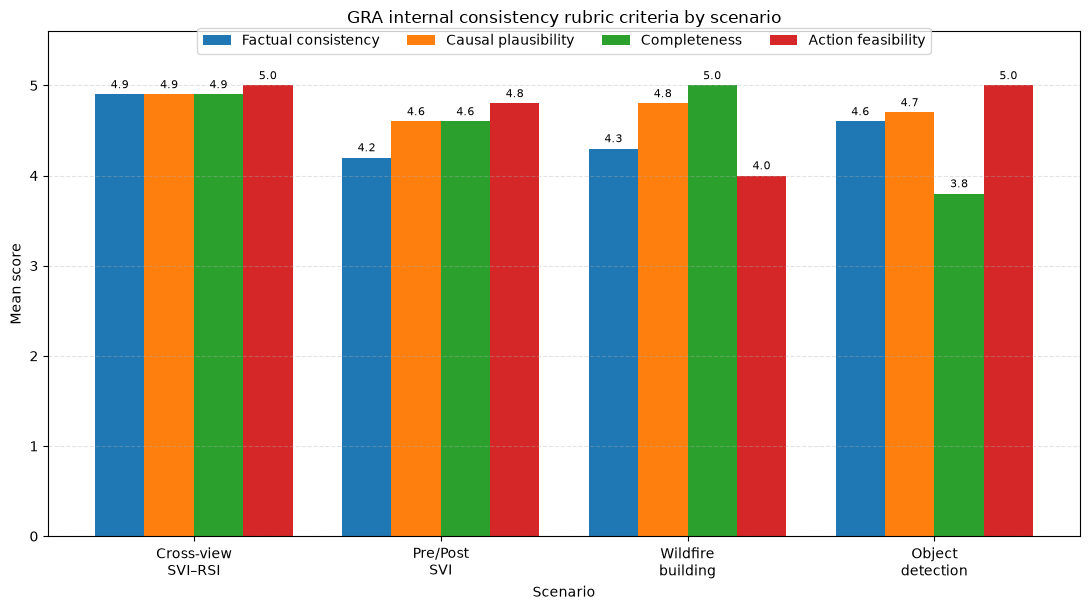

In [63]:
# Rubric criteria by scenario for GRA internal consistency evaluation
# Improved version with cleaner legend placement

plot_df = (
    gra_internal_by_scenario
    .set_index("scenario")
    .loc[scenario_order]
    .reset_index()
)

criteria = [
    "factual_consistency",
    "causal_plausibility",
    "completeness",
    "action_feasibility",
]

criterion_labels = [
    "Factual consistency",
    "Causal plausibility",
    "Completeness",
    "Action feasibility",
]

x = np.arange(len(plot_df))
width = 0.20

plt.figure(figsize=(11, 6.2))

for i, criterion in enumerate(criteria):
    bars = plt.bar(
        x + i * width,
        plot_df[criterion],
        width,
        label=criterion_labels[i],
    )

    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.04,
            f"{height:.1f}",
            ha="center",
            va="bottom",
            fontsize=8,
        )

plt.xticks(
    x + width * 1.5,
    plot_df["scenario_label"],
)

plt.ylim(0, 5.6)
plt.ylabel("Mean score")
plt.xlabel("Scenario")
plt.title("GRA internal consistency rubric criteria by scenario")
plt.grid(axis="y", linestyle="--", alpha=0.35)

plt.legend(
    frameon=True,
    ncol=4,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
)

save_fig("gra_internal_consistency_criteria_by_scenario.png")

### 7.5 Overall Interpretation of GRA Internal Consistency Evaluation

The GeoReasoning Agent achieved strong internal consistency performance across the evaluated reports. Out of 40 successfully evaluated reports, 32 were classified as pass, 6 as borderline, and 2 as fail. The overall mean rubric score was 4.63 out of 5.

The strongest criterion was causal plausibility, with a mean score of 4.75, followed by action feasibility at 4.70, completeness at 4.58, and factual consistency at 4.50. These results indicate that the generated reports generally remain faithful to the structured upstream evidence, provide plausible causal interpretations, cover the expected report components, and propose realistic follow-up actions.

At scenario level, cross-view SVI–RSI achieved the highest overall mean score, reaching 4.92 out of 5. The remaining scenarios also achieved high scores, with Pre/Post SVI at 4.55, Wildfire building at 4.53, and Object detection at 4.53. This suggests that the GeoReasoning Agent is robust across different input configurations and report types.

The criterion-level analysis also reveals scenario-specific weaknesses. Wildfire-building reports achieved high completeness but lower action feasibility, while object-detection reports achieved high action feasibility but lower completeness. Overall, this evaluation shows that HERMES can generate internally consistent and evidence-grounded disaster-response reports, although some scenarios still require improvement in completeness or operational specificity.

### 7.6 Figure Captions for Thesis

**Figure X. Mean rubric scores for GeoReasoning Agent internal consistency evaluation.**  
Mean scores across the four internal-consistency rubric criteria. The generated reports achieved high scores for factual consistency, causal plausibility, completeness, and action feasibility, resulting in an overall mean score of 4.63 out of 5.

**Figure X. Verdict distribution for the GeoReasoning Agent internal consistency evaluation.**  
Distribution of pass, borderline, and fail verdicts across 40 successfully evaluated reports. Most reports were classified as pass, indicating strong overall report faithfulness and internal consistency.

**Figure X. Overall internal-consistency score by scenario for the GeoReasoning Agent.**  
Mean overall rubric score by scenario. All scenarios achieved high scores, with cross-view SVI–RSI reaching the strongest performance.

**Figure X. Rubric-criterion scores by scenario for the GeoReasoning Agent internal consistency evaluation.**  
Scenario-level breakdown of factual consistency, causal plausibility, completeness, and action feasibility. The results show consistently strong report quality, while also revealing scenario-specific weaknesses in completeness or action feasibility.

## 8. Evaluation 6 — GeoReasoning Agent Strict Operational Quality Evaluation

This evaluation assesses the strict operational quality of the reports generated by the GeoReasoning Agent.

Unlike the internal consistency evaluation, which focuses on coherence and faithfulness to upstream evidence, this evaluation applies a stricter operational rubric. It examines whether the generated reports provide sufficiently specific, evidence-aligned, uncertainty-aware, and decision-supportive information for practical disaster-response use.

The strict operational rubric includes four criteria:

- Operational specificity
- Evidence-action alignment
- Uncertainty and risk handling
- Decision-support value

Each criterion is scored on a 1–5 scale. This evaluation is intended to identify the gap between internally consistent report generation and genuinely operational disaster decision support.

In [64]:
gra_strict_scores = load_csv(
    "evaluation/gra_report_evaluation_set/strict_operational_evaluation/gra_strict_operational_scores.csv"
)

gra_strict_scores = clean_columns(gra_strict_scores)

print("GRA strict operational scores shape:", gra_strict_scores.shape)
print("Columns:")
print(gra_strict_scores.columns.tolist())

gra_strict_scores.head(10)

GRA strict operational scores shape: (40, 20)
Columns:
['run_timestamp', 'scenario', 'case_id', 'report_json_path', 'status', 'model', 'operational_specificity', 'evidence_action_alignment', 'uncertainty_risk_handling', 'decision_support_value', 'overall_mean', 'overall_verdict', 'major_issues', 'recommended_improvements', 'operational_specificity_rationale', 'evidence_action_alignment_rationale', 'uncertainty_risk_handling_rationale', 'decision_support_value_rationale', 'raw_eval_json', 'error_summary']


,run_timestamp,scenario,case_id,report_json_path,status,model,operational_specificity,evidence_action_alignment,uncertainty_risk_handling,decision_support_value,overall_mean,overall_verdict,major_issues,recommended_improvements,operational_specificity_rationale,evidence_action_alignment_rationale,uncertainty_risk_handling_rationale,decision_support_value_rationale,raw_eval_json,error_summary
0,2026-08-26T08:33:08,cross_view_svi_rsi,133774193036070_Satellite__133774193036070_SVI,evaluation\gra_report_evaluation_set\cross_view_svi_rsi\reports\133774193036070\cross_view_svi_rsi__133774193036070_Satellite__133774193036070_SVI_report.json,success,gemini-3.1-pro-preview,2,4,4,3,3.25,borderline,"[""Inclusion of irrelevant local file paths (e.g., 'outputs/restored\\\\...')."", ""Exposure of internal system mechanics, agent names, and raw image-quality m...","[""Remove all references to internal system architecture, agent names, and local file paths."", ""Translate image-quality improvements into plain language (e.g...","The report includes highly specific and relevant damage descriptions (e.g., defoliated trees, damaged palm fronds, roadside debris piles). However, it is se...",The recommended actions align very well with the observed evidence. The call to prioritize debris removal and verify road accessibility directly addresses t...,"The report effectively communicates its limitations, explicitly stating it is a rapid situational-awareness product and not a definitive engineering inspect...","The report provides clear, actionable intelligence for public works and debris-clearing teams by identifying vegetation debris as the primary operational hu...","{""operational_specificity"": {""score"": 2, ""rationale"": ""The report includes highly specific and relevant damage descriptions (e.g., defoliated trees, damaged...",NaN
1,2026-08-26T08:33:26,cross_view_svi_rsi,137433545842697_Satellite__137433545842697_SVI,evaluation\gra_report_evaluation_set\cross_view_svi_rsi\reports\137433545842697\cross_view_svi_rsi__137433545842697_Satellite__137433545842697_SVI_report.json,success,gemini-3.1-pro-preview,2,3,4,3,3.00,borderline,"[""Inclusion of raw local file paths and internal directory structures."", ""Inclusion of raw, unformatted floating-point quality scores (Q_before, Q_after)."",...","[""Remove all internal system references, local file paths, and raw metrics from the final user-facing product."", ""Tailor recommended actions to the specific...","The report contains severe violations of user-facing formatting, including raw local file paths ('data\\hermes_benchmark\\...') and uninterpretable raw floa...","The report explicitly states that roads are clear and dry with 'no visible standing water', yet the recommended actions advise checking for 'localized flood...","The report effectively communicates the limitations of the assessment, correctly noting the inherent differences in viewpoints between RSI and SVI. It also ...","The identification of clear roads and moderate vegetation damage is useful for routing and debris-clearing prioritization. However, the heavy inclusion of d...","{""operational_specificity"": {""score"": 2, ""rationale"": ""The report contains severe violations of user-facing formatting, including raw local file paths ('dat...",NaN
2,2026-08-26T08:33:44,cross_view_svi_rsi,137583195510477_Satellite__137583195510477_SVI,evaluation\gra_report_evaluation_set\cross_view_svi_rsi\reports\137583195510477\cross_view_svi_rsi__137583195510477_Satellite__137583195510477_SVI_report.json,success,gemini-3.1-pro-preview,2,5,5,4,4.00,borderline,"[""Inclusion of internal local file paths (e.g., 'outputs/restored\\\\...') in a user-facing report."", ""Exposure of raw backend metrics and arrays (e.g., Q_b...","[""Remove all internal file paths and raw numerical arrays from the final report."", ""Translate image quality and restoration steps into plain operational lan...","The report contains highly specific and relevant damage observation

In [65]:
# Inspect status, scenarios, and verdict distribution before plotting

print("Status values:")
print(gra_strict_scores["status"].value_counts(dropna=False))
print()

print("Scenario values:")
print(gra_strict_scores["scenario"].value_counts(dropna=False))
print()

print("Verdict values:")
print(gra_strict_scores["overall_verdict"].value_counts(dropna=False))

Status values:
status
success    40
Name: count, dtype: int64

Scenario values:
scenario
cross_view_svi_rsi    10
pre_post_svi          10
wildfire_building     10
object_detection      10
Name: count, dtype: int64

Verdict values:
overall_verdict
borderline    25
fail          15
Name: count, dtype: int64


In [66]:
# Keep only successfully evaluated strict operational reports

gra_strict_valid = gra_strict_scores[
    gra_strict_scores["status"] == "success"
].copy()

gra_strict_valid = coerce_numeric(
    gra_strict_valid,
    [
        "operational_specificity",
        "evidence_action_alignment",
        "uncertainty_risk_handling",
        "decision_support_value",
        "overall_mean",
    ]
)

print("Valid GRA strict operational reports:", len(gra_strict_valid))
print()

print("Scenario distribution:")
print(gra_strict_valid["scenario"].value_counts())
print()

print("Verdict distribution:")
print(gra_strict_valid["overall_verdict"].value_counts())

gra_strict_valid.head()

Valid GRA strict operational reports: 40

Scenario distribution:
scenario
cross_view_svi_rsi    10
pre_post_svi          10
wildfire_building     10
object_detection      10
Name: count, dtype: int64

Verdict distribution:
overall_verdict
borderline    25
fail          15
Name: count, dtype: int64


,run_timestamp,scenario,case_id,report_json_path,status,model,operational_specificity,evidence_action_alignment,uncertainty_risk_handling,decision_support_value,overall_mean,overall_verdict,major_issues,recommended_improvements,operational_specificity_rationale,evidence_action_alignment_rationale,uncertainty_risk_handling_rationale,decision_support_value_rationale,raw_eval_json,error_summary
0,2026-08-26T08:33:08,cross_view_svi_rsi,133774193036070_Satellite__133774193036070_SVI,evaluation\gra_report_evaluation_set\cross_view_svi_rsi\reports\133774193036070\cross_view_svi_rsi__133774193036070_Satellite__133774193036070_SVI_report.json,success,gemini-3.1-pro-preview,2,4,4,3,3.25,borderline,"[""Inclusion of irrelevant local file paths (e.g., 'outputs/restored\\\\...')."", ""Exposure of internal system mechanics, agent names, and raw image-quality m...","[""Remove all references to internal system architecture, agent names, and local file paths."", ""Translate image-quality improvements into plain language (e.g...","The report includes highly specific and relevant damage descriptions (e.g., defoliated trees, damaged palm fronds, roadside debris piles). However, it is se...",The recommended actions align very well with the observed evidence. The call to prioritize debris removal and verify road accessibility directly addresses t...,"The report effectively communicates its limitations, explicitly stating it is a rapid situational-awareness product and not a definitive engineering inspect...","The report provides clear, actionable intelligence for public works and debris-clearing teams by identifying vegetation debris as the primary operational hu...","{""operational_specificity"": {""score"": 2, ""rationale"": ""The report includes highly specific and relevant damage descriptions (e.g., defoliated trees, damaged...",NaN
1,2026-08-26T08:33:26,cross_view_svi_rsi,137433545842697_Satellite__137433545842697_SVI,evaluation\gra_report_evaluation_set\cross_view_svi_rsi\reports\137433545842697\cross_view_svi_rsi__137433545842697_Satellite__137433545842697_SVI_report.json,success,gemini-3.1-pro-preview,2,3,4,3,3.00,borderline,"[""Inclusion of raw local file paths and internal directory structures."", ""Inclusion of raw, unformatted floating-point quality scores (Q_before, Q_after)."",...","[""Remove all internal system references, local file paths, and raw metrics from the final user-facing product."", ""Tailor recommended actions to the specific...","The report contains severe violations of user-facing formatting, including raw local file paths ('data\\hermes_benchmark\\...') and uninterpretable raw floa...","The report explicitly states that roads are clear and dry with 'no visible standing water', yet the recommended actions advise checking for 'localized flood...","The report effectively communicates the limitations of the assessment, correctly noting the inherent differences in viewpoints between RSI and SVI. It also ...","The identification of clear roads and moderate vegetation damage is useful for routing and debris-clearing prioritization. However, the heavy inclusion of d...","{""operational_specificity"": {""score"": 2, ""rationale"": ""The report contains severe violations of user-facing formatting, including raw local file paths ('dat...",NaN
2,2026-08-26T08:33:44,cross_view_svi_rsi,137583195510477_Satellite__137583195510477_SVI,evaluation\gra_report_evaluation_set\cross_view_svi_rsi\reports\137583195510477\cross_view_svi_rsi__137583195510477_Satellite__137583195510477_SVI_report.json,success,gemini-3.1-pro-preview,2,5,5,4,4.00,borderline,"[""Inclusion of internal local file paths (e.g., 'outputs/restored\\\\...') in a user-facing report."", ""Exposure of raw backend metrics and arrays (e.g., Q_b...","[""Remove all internal file paths and raw numerical arrays from the final report."", ""Translate image quality and restoration steps into plain operational lan...","The report contains highly specific and relevant damage observation

In [67]:
# Overall rubric-score summary for GRA strict operational quality evaluation

gra_strict_criteria = [
    "operational_specificity",
    "evidence_action_alignment",
    "uncertainty_risk_handling",
    "decision_support_value",
    "overall_mean",
]

gra_strict_overall_summary = pd.DataFrame([
    {
        "criterion": "Operational specificity",
        "mean_score": gra_strict_valid["operational_specificity"].mean(),
    },
    {
        "criterion": "Evidence-action alignment",
        "mean_score": gra_strict_valid["evidence_action_alignment"].mean(),
    },
    {
        "criterion": "Uncertainty/risk handling",
        "mean_score": gra_strict_valid["uncertainty_risk_handling"].mean(),
    },
    {
        "criterion": "Decision-support value",
        "mean_score": gra_strict_valid["decision_support_value"].mean(),
    },
    {
        "criterion": "Overall mean",
        "mean_score": gra_strict_valid["overall_mean"].mean(),
    },
])

gra_strict_overall_summary

,criterion,mean_score
0,Operational specificity,1.7000
1,Evidence-action alignment,3.1250
2,Uncertainty/risk handling,3.3500
3,Decision-support value,2.5750
4,Overall mean,2.6875


Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gra_strict_operational_rubric_scores.png


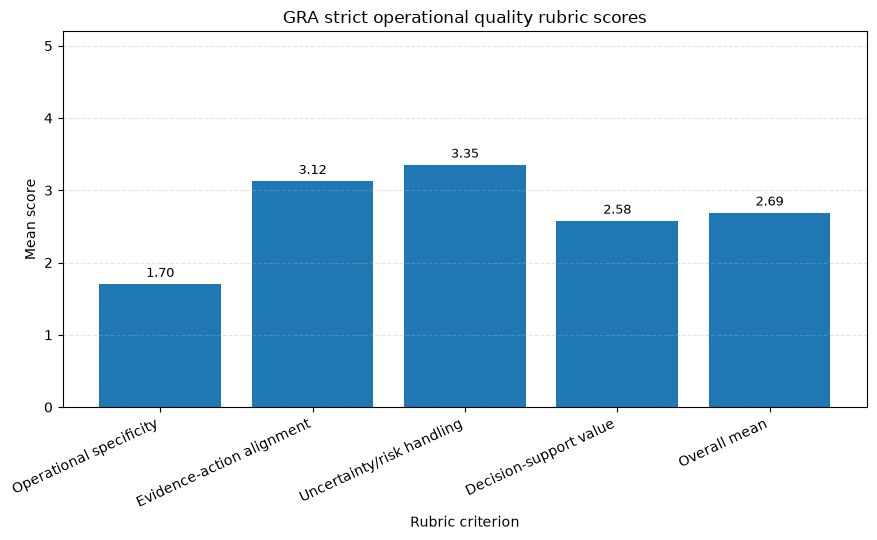

In [68]:
# Overall rubric scores for GRA strict operational quality evaluation

plot_df = gra_strict_overall_summary.copy()

plt.figure(figsize=(9, 5.5))

bars = plt.bar(
    plot_df["criterion"],
    plot_df["mean_score"],
)

plt.ylim(0, 5.2)
plt.ylabel("Mean score")
plt.xlabel("Rubric criterion")
plt.title("GRA strict operational quality rubric scores")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.35)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.06,
        f"{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

save_fig("gra_strict_operational_rubric_scores.png")

Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gra_strict_operational_verdict_distribution.png


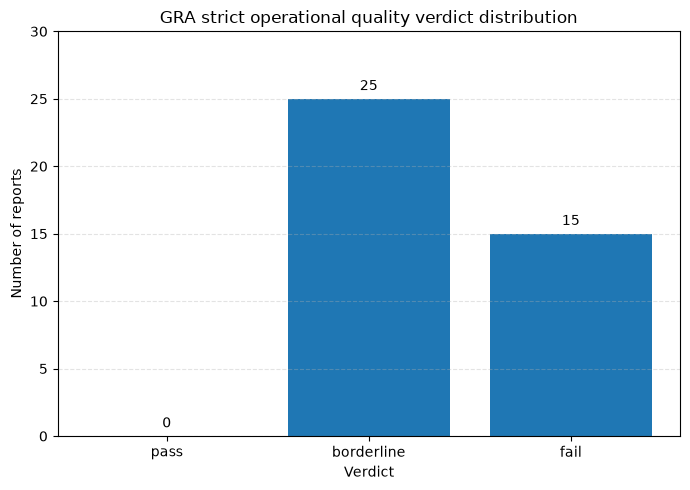

In [69]:
# Verdict distribution for GRA strict operational quality evaluation

verdict_order = ["pass", "borderline", "fail"]

gra_strict_verdict_counts = (
    gra_strict_valid["overall_verdict"]
    .value_counts()
    .reindex(verdict_order)
    .fillna(0)
    .astype(int)
    .reset_index()
)

gra_strict_verdict_counts.columns = ["verdict", "count"]

plt.figure(figsize=(7, 5))

bars = plt.bar(
    gra_strict_verdict_counts["verdict"],
    gra_strict_verdict_counts["count"],
)

plt.ylabel("Number of reports")
plt.xlabel("Verdict")
plt.title("GRA strict operational quality verdict distribution")
plt.ylim(0, gra_strict_verdict_counts["count"].max() + 5)
plt.grid(axis="y", linestyle="--", alpha=0.35)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.4,
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontsize=10,
    )

save_fig("gra_strict_operational_verdict_distribution.png")

In [70]:
# Mean strict operational scores by scenario

gra_strict_by_scenario = (
    gra_strict_valid
    .groupby("scenario")[
        [
            "operational_specificity",
            "evidence_action_alignment",
            "uncertainty_risk_handling",
            "decision_support_value",
            "overall_mean",
        ]
    ]
    .mean()
    .reset_index()
)

scenario_label_map = {
    "cross_view_svi_rsi": "Cross-view\nSVI–RSI",
    "pre_post_svi": "Pre/Post\nSVI",
    "wildfire_building": "Wildfire\nbuilding",
    "object_detection": "Object\ndetection",
}

gra_strict_by_scenario["scenario_label"] = (
    gra_strict_by_scenario["scenario"]
    .map(scenario_label_map)
    .fillna(gra_strict_by_scenario["scenario"])
)

gra_strict_by_scenario

,scenario,operational_specificity,evidence_action_alignment,uncertainty_risk_handling,decision_support_value,overall_mean,scenario_label
0,cross_view_svi_rsi,2.0,3.7,3.9,3.2,3.200,Cross-view\nSVI–RSI
1,object_detection,1.6,3.8,3.7,2.8,2.975,Object\ndetection
2,pre_post_svi,1.6,3.4,3.1,2.6,2.675,Pre/Post\nSVI
3,wildfire_building,1.6,1.6,2.7,1.7,1.900,Wildfire\nbuilding


Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gra_strict_operational_overall_score_by_scenario.png


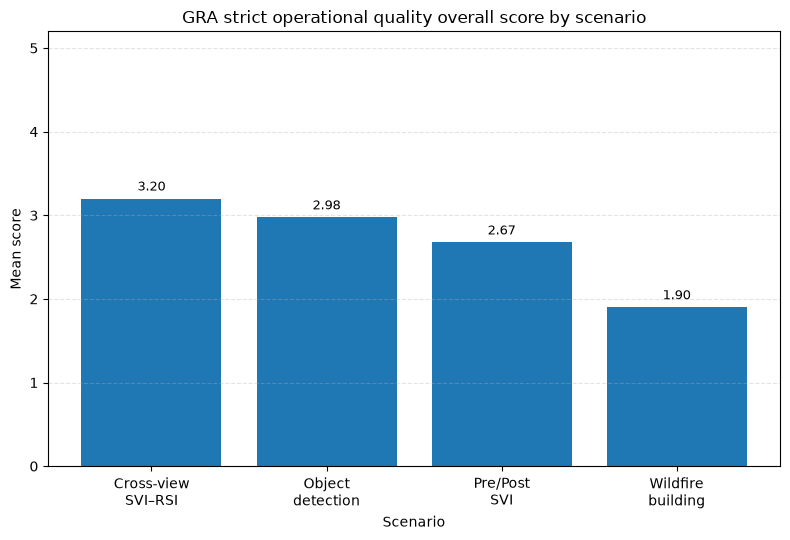

In [71]:
# Overall strict operational quality score by scenario

scenario_order = [
    "cross_view_svi_rsi",
    "object_detection",
    "pre_post_svi",
    "wildfire_building",
]

plot_df = (
    gra_strict_by_scenario
    .set_index("scenario")
    .loc[scenario_order]
    .reset_index()
)

plt.figure(figsize=(8, 5.5))

bars = plt.bar(
    plot_df["scenario_label"],
    plot_df["overall_mean"],
)

plt.ylim(0, 5.2)
plt.ylabel("Mean score")
plt.xlabel("Scenario")
plt.title("GRA strict operational quality overall score by scenario")
plt.grid(axis="y", linestyle="--", alpha=0.35)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.06,
        f"{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

save_fig("gra_strict_operational_overall_score_by_scenario.png")

Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gra_strict_operational_criteria_by_scenario.png


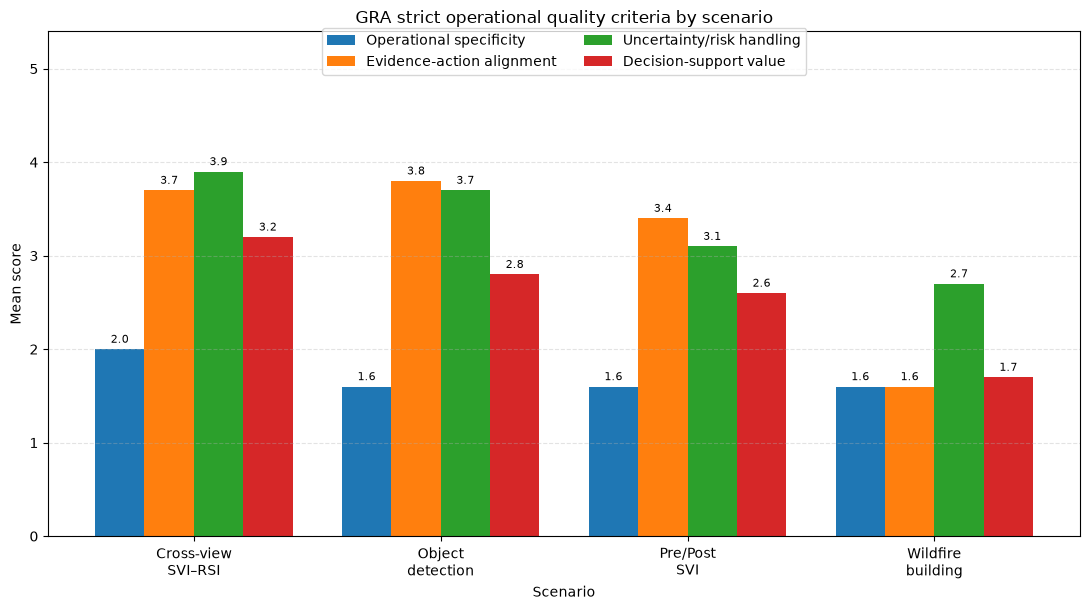

In [72]:
# Strict operational rubric criteria by scenario

plot_df = (
    gra_strict_by_scenario
    .set_index("scenario")
    .loc[scenario_order]
    .reset_index()
)

criteria = [
    "operational_specificity",
    "evidence_action_alignment",
    "uncertainty_risk_handling",
    "decision_support_value",
]

criterion_labels = [
    "Operational specificity",
    "Evidence-action alignment",
    "Uncertainty/risk handling",
    "Decision-support value",
]

x = np.arange(len(plot_df))
width = 0.20

plt.figure(figsize=(11, 6.2))

for i, criterion in enumerate(criteria):
    bars = plt.bar(
        x + i * width,
        plot_df[criterion],
        width,
        label=criterion_labels[i],
    )

    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.04,
            f"{height:.1f}",
            ha="center",
            va="bottom",
            fontsize=8,
        )

plt.xticks(
    x + width * 1.5,
    plot_df["scenario_label"],
)

plt.ylim(0, 5.4)
plt.ylabel("Mean score")
plt.xlabel("Scenario")
plt.title("GRA strict operational quality criteria by scenario")
plt.grid(axis="y", linestyle="--", alpha=0.35)

plt.legend(
    frameon=True,
    ncol=2,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
)

save_fig("gra_strict_operational_criteria_by_scenario.png")

Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\gra_strict_operational_verdict_distribution_by_scenario.png


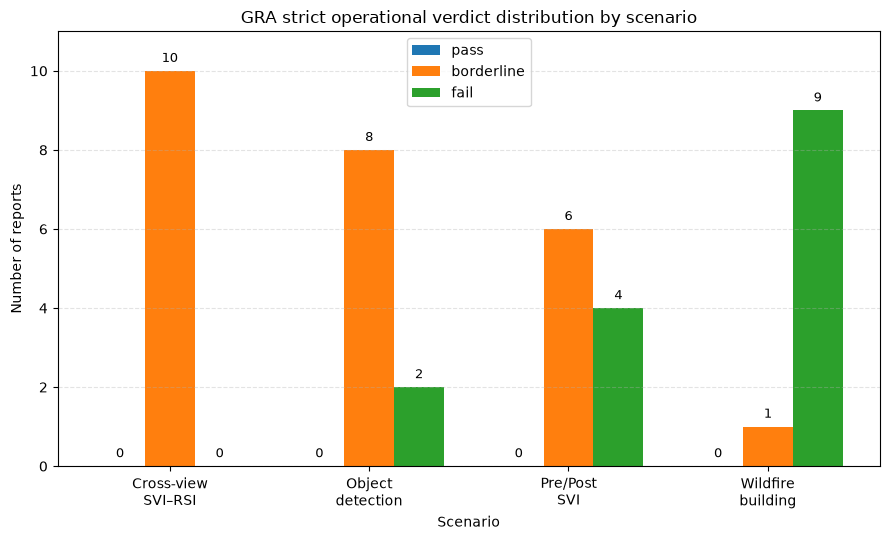

In [73]:
# Strict operational verdict distribution by scenario

verdict_order = ["pass", "borderline", "fail"]

gra_strict_verdict_by_scenario = (
    gra_strict_valid
    .groupby(["scenario", "overall_verdict"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=verdict_order, fill_value=0)
    .reset_index()
)

scenario_label_map = {
    "cross_view_svi_rsi": "Cross-view\nSVI–RSI",
    "object_detection": "Object\ndetection",
    "pre_post_svi": "Pre/Post\nSVI",
    "wildfire_building": "Wildfire\nbuilding",
}

gra_strict_verdict_by_scenario["scenario_label"] = (
    gra_strict_verdict_by_scenario["scenario"]
    .map(scenario_label_map)
    .fillna(gra_strict_verdict_by_scenario["scenario"])
)

scenario_order = [
    "cross_view_svi_rsi",
    "object_detection",
    "pre_post_svi",
    "wildfire_building",
]

plot_df = (
    gra_strict_verdict_by_scenario
    .set_index("scenario")
    .loc[scenario_order]
    .reset_index()
)

x = np.arange(len(plot_df))
width = 0.25

plt.figure(figsize=(9, 5.5))

for i, verdict in enumerate(verdict_order):
    bars = plt.bar(
        x + i * width,
        plot_df[verdict],
        width,
        label=verdict,
    )

    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.15,
            f"{int(height)}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

plt.xticks(
    x + width,
    plot_df["scenario_label"],
)

plt.ylabel("Number of reports")
plt.xlabel("Scenario")
plt.title("GRA strict operational verdict distribution by scenario")
plt.ylim(0, 11)
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(frameon=True)

save_fig("gra_strict_operational_verdict_distribution_by_scenario.png")

In [74]:
# Final summary table for GRA strict operational quality evaluation

strict_verdict_counts = (
    gra_strict_valid["overall_verdict"]
    .value_counts()
    .to_dict()
)

best_strict_scenario = (
    gra_strict_by_scenario
    .sort_values("overall_mean", ascending=False)
    .iloc[0]
)

weakest_strict_scenario = (
    gra_strict_by_scenario
    .sort_values("overall_mean", ascending=True)
    .iloc[0]
)

gra_strict_final_summary = pd.DataFrame([
    {
        "metric": "Evaluated reports",
        "value": len(gra_strict_valid),
    },
    {
        "metric": "Overall mean score",
        "value": gra_strict_valid["overall_mean"].mean(),
    },
    {
        "metric": "Operational specificity",
        "value": gra_strict_valid["operational_specificity"].mean(),
    },
    {
        "metric": "Evidence-action alignment",
        "value": gra_strict_valid["evidence_action_alignment"].mean(),
    },
    {
        "metric": "Uncertainty/risk handling",
        "value": gra_strict_valid["uncertainty_risk_handling"].mean(),
    },
    {
        "metric": "Decision-support value",
        "value": gra_strict_valid["decision_support_value"].mean(),
    },
    {
        "metric": "Pass verdicts",
        "value": strict_verdict_counts.get("pass", 0),
    },
    {
        "metric": "Borderline verdicts",
        "value": strict_verdict_counts.get("borderline", 0),
    },
    {
        "metric": "Fail verdicts",
        "value": strict_verdict_counts.get("fail", 0),
    },
    {
        "metric": "Best scenario",
        "value": best_strict_scenario["scenario"],
    },
    {
        "metric": "Weakest scenario",
        "value": weakest_strict_scenario["scenario"],
    },
])

gra_strict_final_summary

,metric,value
0,Evaluated reports,40
1,Overall mean score,2.6875
2,Operational specificity,1.7
3,Evidence-action alignment,3.125
4,Uncertainty/risk handling,3.35
5,Decision-support value,2.575
6,Pass verdicts,0
7,Borderline verdicts,25
8,Fail verdicts,15
9,Best scenario,cross_view_svi_rsi


### 8.6 Overall Interpretation of GRA Strict Operational Quality Evaluation

The strict operational quality evaluation revealed a substantial gap between internally consistent report generation and operationally mature disaster decision support. Across 40 evaluated reports, the GeoReasoning Agent achieved an overall mean score of 2.6875 out of 5. None of the reports received a pass verdict; 25 were classified as borderline and 15 as fail.

The weakest criterion was operational specificity, with a mean score of 1.70. This indicates that many reports lacked sufficiently concrete, field-ready detail for direct operational use. Decision-support value was also limited, with a mean score of 2.575. In contrast, uncertainty and risk handling achieved the strongest score at 3.35, followed by evidence-action alignment at 3.125. This suggests that the reports often acknowledged uncertainty and maintained partial alignment between observations and recommendations, but did not consistently translate the evidence into specific operational guidance.

Scenario-level results further highlight this limitation. Cross-view SVI–RSI achieved the strongest strict operational score, with an overall mean of 3.20, followed by object detection at 2.975 and Pre/Post SVI at 2.675. Wildfire building was the weakest scenario, with an overall mean of 1.90 and 9 out of 10 reports classified as fail.

Overall, this evaluation shows that while HERMES can generate coherent and evidence-grounded reports, additional work is required to make those reports operationally mature. Future improvements should focus on removing internal system artifacts, increasing the specificity of recommended actions, improving scenario-specific guidance, and translating technical observations into directly usable decision-support outputs.

### 8.7 Figure Captions for Thesis

**Figure X. Mean rubric scores for the GeoReasoning Agent strict operational quality evaluation.**  
Mean scores across the strict operational rubric criteria. The reports achieved moderate scores for evidence-action alignment and uncertainty/risk handling, but low operational specificity and decision-support value, resulting in an overall mean score of 2.69 out of 5.

**Figure X. Verdict distribution for the GeoReasoning Agent strict operational quality evaluation.**  
Distribution of pass, borderline, and fail verdicts across 40 evaluated reports. No report achieved a pass verdict under the strict operational rubric, while 25 reports were classified as borderline and 15 as fail.

**Figure X. Overall strict operational quality score by scenario for the GeoReasoning Agent.**  
Mean strict operational quality score by scenario. Cross-view SVI–RSI achieved the highest score, while wildfire-building reports showed the weakest operational quality.

**Figure X. Strict operational quality criteria by scenario for the GeoReasoning Agent.**  
Scenario-level breakdown of operational specificity, evidence-action alignment, uncertainty/risk handling, and decision-support value. Operational specificity remains low across all scenarios, while wildfire-building reports show the weakest performance across most criteria.

**Figure X. Strict operational verdict distribution by scenario for the GeoReasoning Agent.**  
Verdict distribution by scenario under the strict operational rubric. Cross-view SVI–RSI reports were consistently borderline, while wildfire-building reports were predominantly classified as fail.

## 9. Cross-Evaluation Summary

This section summarizes the six completed HERMES evaluations.

The goal is to compare performance across perception, damage analysis, object-indicator extraction, and reasoning/report-generation components. The combined results show where HERMES performs strongly and where the main technical bottlenecks remain.

The six evaluation blocks are:

1. GeoPerception Agent — hazard classification
2. GeoPerception Agent — input-mode recognition
3. GeoDamageAnalysis Agent — severity evaluation
4. GeoDamageAnalysis Agent — object-indicator evaluation
5. GeoReasoning Agent — internal consistency evaluation
6. GeoReasoning Agent — strict operational quality evaluation

In [75]:
# Cross-evaluation summary table

cross_evaluation_summary = pd.DataFrame([
    {
        "evaluation": "1. GPA hazard classification",
        "main_metric": "Overall accuracy",
        "score": overall_hazard_accuracy,
        "interpretation": "Strong closed-set hazard recognition",
    },
    {
        "evaluation": "2. GPA input-mode recognition",
        "main_metric": "Overall accuracy",
        "score": overall_mode_accuracy,
        "interpretation": "Very strong routing / input-configuration recognition",
    },
    {
        "evaluation": "3. GDAA severity evaluation",
        "main_metric": "Overall exact accuracy",
        "score": gdaa_severity_final_summary.loc[
            gdaa_severity_final_summary["metric"] == "Overall exact severity accuracy",
            "value"
        ].iloc[0],
        "interpretation": "Ordinal severity estimation remains difficult",
    },
    {
        "evaluation": "4. GDAA object-indicator evaluation",
        "main_metric": "Micro F1",
        "score": gdaa_object_final_summary.loc[
            gdaa_object_final_summary["metric"] == "Micro F1",
            "value"
        ].iloc[0],
        "interpretation": "Useful multi-label signal extraction, but recall-oriented",
    },
    {
        "evaluation": "5. GRA internal consistency evaluation",
        "main_metric": "Overall mean score",
        "score": gra_internal_overall_summary.loc[
            gra_internal_overall_summary["criterion"] == "Overall mean",
            "mean_score"
        ].iloc[0],
        "interpretation": "Generated reports are internally consistent and evidence-grounded",
    },
    {
        "evaluation": "6. GRA strict operational quality evaluation",
        "main_metric": "Overall mean score",
        "score": gra_strict_overall_summary.loc[
            gra_strict_overall_summary["criterion"] == "Overall mean",
            "mean_score"
        ].iloc[0],
        "interpretation": "Operational decision-support quality remains limited",
    },
])

cross_evaluation_summary

,evaluation,main_metric,score,interpretation
0,1. GPA hazard classification,Overall accuracy,0.909500,Strong closed-set hazard recognition
1,2. GPA input-mode recognition,Overall accuracy,0.982800,Very strong routing / input-configuration recognition
2,3. GDAA severity evaluation,Overall exact accuracy,0.467227,Ordinal severity estimation remains difficult
3,4. GDAA object-indicator evaluation,Micro F1,0.696491,"Useful multi-label signal extraction, but recall-oriented"
4,5. GRA internal consistency evaluation,Overall mean score,4.631250,Generated reports are internally consistent and evidence-grounded
5,6. GRA strict operational quality evaluation,Overall mean score,2.687500,Operational decision-support quality remains limited


In [77]:
# Normalize cross-evaluation scores for visualization

cross_evaluation_plot = cross_evaluation_summary.copy()

def normalize_cross_eval_score(row):
    if "Overall mean score" in row["main_metric"]:
        return row["score"] / 5.0
    return row["score"]

cross_evaluation_plot["normalized_score"] = cross_evaluation_plot.apply(
    normalize_cross_eval_score,
    axis=1,
)

cross_evaluation_plot["short_label"] = [
    "Hazard\nclassification",
    "Input-mode\nrecognition",
    "Severity\nevaluation",
    "Object-indicator\ndetection",
    "Internal\nconsistency",
    "Strict operational\nquality",
]

cross_evaluation_plot

,evaluation,main_metric,score,interpretation,normalized_score,short_label
0,1. GPA hazard classification,Overall accuracy,0.909500,Strong closed-set hazard recognition,0.909500,Hazard\nclassification
1,2. GPA input-mode recognition,Overall accuracy,0.982800,Very strong routing / input-configuration recognition,0.982800,Input-mode\nrecognition
2,3. GDAA severity evaluation,Overall exact accuracy,0.467227,Ordinal severity estimation remains difficult,0.467227,Severity\nevaluation
3,4. GDAA object-indicator evaluation,Micro F1,0.696491,"Useful multi-label signal extraction, but recall-oriented",0.696491,Object-indicator\ndetection
4,5. GRA internal consistency evaluation,Overall mean score,4.631250,Generated reports are internally consistent and evidence-grounded,0.926250,Internal\nconsistency
5,6. GRA strict operational quality evaluation,Overall mean score,2.687500,Operational decision-support quality remains limited,0.537500,Strict operational\nquality


Saved figure: e:\Msc_GeoInformatics_Nomikos\Thesis\HERMES\hermes\figures\evaluation_visualizations\hermes_cross_evaluation_summary.png


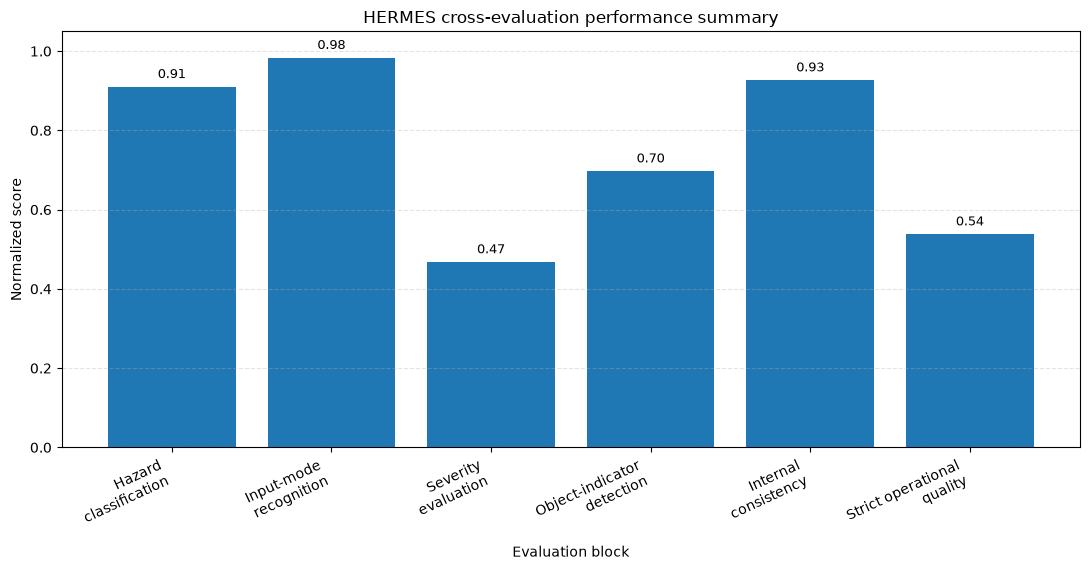

In [78]:
# Cross-evaluation normalized performance summary

plot_df = cross_evaluation_plot.copy()

plt.figure(figsize=(11, 5.8))

bars = plt.bar(
    plot_df["short_label"],
    plot_df["normalized_score"],
)

plt.ylim(0, 1.05)
plt.ylabel("Normalized score")
plt.xlabel("Evaluation block")
plt.title("HERMES cross-evaluation performance summary")
plt.grid(axis="y", linestyle="--", alpha=0.35)

for bar, score in zip(bars, plot_df["normalized_score"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.015,
        f"{score:.2f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

plt.xticks(rotation=25, ha="right")

save_fig("hermes_cross_evaluation_summary.png")

### 9.1 Interpretation of Cross-Evaluation Results

The cross-evaluation summary shows that HERMES performs strongly in perception and report coherence, but faces greater difficulty in fine-grained damage assessment and strict operational reporting.

The strongest result is input-mode recognition, with a normalized score of 0.98, showing that the GeoPerception Agent can reliably identify the input configuration and support downstream routing. Hazard classification also performs strongly, with an accuracy of 0.91. The GeoReasoning Agent achieves a high normalized internal-consistency score of 0.93, indicating that the generated reports are generally coherent, plausible, complete, and evidence-grounded.

In contrast, severity evaluation remains the main damage-analysis bottleneck, with an exact accuracy of 0.47. Object-indicator detection achieves a moderate micro F1-score of 0.70, suggesting that HERMES can extract useful multi-label damage signals, but still shows false-positive behavior and class-imbalance limitations.

The most important contrast is between internal consistency and strict operational quality. While the GeoReasoning Agent performs strongly under the internal consistency rubric, its strict operational quality score drops to 0.54. This indicates that a report can be factually coherent and aligned with upstream evidence without yet being sufficiently specific, actionable, and decision-supportive for operational disaster-response use.

Overall, the evaluation identifies three main strengths: reliable input-mode recognition, strong hazard classification, and internally consistent report generation. It also identifies three main limitations: ordinal severity estimation, rare object-indicator detection, and operational report maturity.

## 10. Key Findings and Conclusion

The evaluation of HERMES across six experimental blocks shows that the system performs strongly in perception, input routing, and internally consistent report generation, while more demanding damage-assessment and operational-reporting tasks remain challenging.

The strongest technical result was achieved in input-mode recognition, where the GeoPerception Agent reached 0.9828 accuracy. This indicates that HERMES can reliably identify the evidence configuration of each case and route inputs to the appropriate downstream workflow. Hazard classification also performed strongly, with 0.9095 overall accuracy, showing that the GeoPerception Agent can effectively recognize closed-set disaster categories.

The GeoDamageAnalysis Agent showed more mixed performance. Severity estimation was the most difficult image-level task, achieving 0.4672 exact accuracy across 595 cases. The results indicate that ordinal severity classification remains challenging, especially for mild and intermediate damage levels. In contrast, object-indicator detection produced more useful multi-label signals, with a micro F1-score of 0.6965 and micro accuracy of 0.7693. However, this task was recall-oriented and affected by class imbalance, especially for rare indicators such as downed lines.

The report-generation evaluations revealed an important distinction between internal consistency and operational usefulness. Under the internal consistency rubric, the GeoReasoning Agent achieved strong results, with an overall mean score of 4.6313 out of 5 and 32 pass verdicts out of 40 reports. This shows that the generated reports are generally coherent, plausible, complete, and grounded in upstream evidence.

However, under the stricter operational quality rubric, performance dropped substantially. The overall mean score was 2.6875 out of 5, with no pass verdicts, 25 borderline reports, and 15 failed reports. The weakest criterion was operational specificity, indicating that the reports often lacked sufficiently concrete, field-ready recommendations. This demonstrates that evidence-grounded reporting does not automatically imply operational decision-support maturity.

Overall, HERMES demonstrates a viable modular multi-agent GeoAI architecture for disaster analysis. Its main strengths are reliable input-mode recognition, strong hazard classification, useful object-indicator extraction, and internally consistent report generation. Its main limitations are ordinal severity estimation, rare object-indicator detection, and the translation of coherent reports into specific operational guidance. These findings provide a clear direction for future work, particularly toward improving severity modeling, reducing false positives in object-indicator detection, and strengthening the operational structure of GeoReasoning Agent reports.

### 10.1 Thesis-Level Summary

The HERMES evaluation supports four main conclusions:

1. The perception layer is reliable for hazard recognition and highly reliable for input-mode recognition.
2. Fine-grained damage analysis is more difficult, especially ordinal severity estimation.
3. The GeoReasoning Agent can generate internally consistent and evidence-grounded reports.
4. Strict operational decision-support quality remains limited and requires further development.

The main contribution of HERMES is therefore not that it fully solves automated disaster response, but that it demonstrates a structured and interpretable multi-agent pipeline for transforming heterogeneous geospatial evidence into disaster-analysis outputs and evaluable reasoning reports.